# NOV-B1 — Can an 8B model evolve new online bin-packing rules? Temperature vs. decision-token branching vs. an "idea" instruction

**Demo notebook of the artifact `art_k7A5-5vcXY1g` (`method.py`)**

The experiment runs a **FunSearch-style island search** on **online 1-D bin packing**. An LLM (**Qwen3-8B-FP8**, served by vLLM 0.11 with thinking off) repeatedly rewrites a Python function `priority(item, bins)`. The **FunSearch harness** (copied from DeepMind's notebook and re-gated) scores every program by the bins it uses, and a FunSearch programs database picks the parents of the next prompt.

The question is which **sampling knob** gives more distinct, and more useful, programs for the same number of LLM calls (2,000 calls per arm and seed, seeds 0 and 1):

| arm | what changes |
|---|---|
| **T1.0** | plain sampling at temperature 1.0 |
| **T1.6** | temperature 1.6 with top-p 0.95 ("turn up the creativity knob") |
| **DTB** | **decision-token branching** (the proposed operator). Sample 48 tokens, find the code token where the model is most uncertain (highest top-20 entropy), force a rank-2..8 alternative there, then keep sampling |
| **RPB** | placebo for DTB: the same forcing at a *random* eligible position |
| **IDEA** | T1.0 plus one sentence: "write it based on an idea different from the functions above" |
| **NS** | no selection: the parents are always first fit and best fit (a control for the evaluator effect) |

Diversity is measured by **what programs do, not how they look**. Every program is run on 2,000 fixed probe states. Programs whose chosen bins agree on at least 95% of those states fall into the same **behaviour cluster**.

**Full-run results (recorded):**
- **V1 SUPPORTED.** Every core arm's best program beats 0.8 × best fit on both held-out sets.
- **V2 PARTIAL.** DTB finds 3.0× the behaviour clusters of T1.0, but only 1.2× those of T1.6 (the bar was 1.5×), and DTB's best program is the weakest on held-out.
- **V3.** 8 programs were judged NOVEL, all one idea: *prefer a bin whose leftover is a whole multiple of the item size*.
- **V6 PARTIAL.** IDEA offspring rename their parents less often than T1.0 offspring (0.44 vs 0.86).
- **No selection, no progress.** NS never beats best fit.

**What this notebook runs.** LLM sampling needs a 24 GB GPU and the LLM judges need an API key, so those stages are **replayed** from recorded outputs. Everything that runs on a CPU is **re-run live** on a curated subset of 96 recorded LLM calls (`mini_demo_data.json`):
- the harness gate and the construction of the probe states;
- the sandboxed evaluation of every program, checked bin for bin against the recorded run;
- the DTB/RPB fork rule, re-derived from the recorded entropies and RNG seeds;
- the island database and behaviour clustering;
- the held-out check (V1), then V2, V3 and V6 on the subset, and the placebos.

The last section maps the programs in **behaviour space** (a classical MDS of 1 − decision agreement) and on the held-out plane.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the original pipeline logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

## Setup

The install cell follows the Colab pattern:

- `loguru`, which the original scripts log through, is installed everywhere.
- numpy, scipy and matplotlib are installed at Colab's exact versions only outside Colab; Colab already has them.

The imports cell then copies the import block of `method.py` followed by the import blocks of the `src/` modules whose code is inlined in this notebook.

In [2]:
from __future__ import annotations

# ---- method.py (the artifact's entry point): its import block as-is
import os
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---- the import blocks of the src/ modules inlined below (bp, sandbox, gate, probes, cluster, analysis, prompts,
#      engine, search, islands, postsearch, corpus, figures)
import ast
import hashlib
import json
import keyword
import math
import re
import signal
import warnings
from collections import Counter
from typing import Callable

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np  # noqa: E402
from scipy.cluster.hierarchy import fcluster, linkage  # noqa: E402
from scipy.sparse import csr_matrix  # noqa: E402
from scipy.sparse.csgraph import connected_components  # noqa: E402

# ---- notebook additions: inline plots (figures.py saved PDF/PNG files with the Agg backend), and SimpleNamespace,
#      which lets the inlined modules keep calling each other as bp.pack(...), cluster.agreement(...), ...
from types import SimpleNamespace  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402

print("numpy", np.__version__)

numpy 2.0.2


### The demo data

`mini_demo_data.json` is loaded from GitHub, or from a local copy if that fails. It holds **one dataset**: a curated subset of `novb1_search_programs`, in which each example is one LLM search call with the same fields as the artifact's `method_out.json`. It also holds the evaluator's fixed inputs and a summary of the full run.

- **96 examples:**
  - the best program of each of the 12 streams;
  - the 8 programs judged NOVEL;
  - 4 audited programs judged "known family, new parameters";
  - a uniform random sample of 7 calls per main stream (5 arms × 2 seeds) and 2 per NS stream.

  Each example keeps its code, recorded F, error class, 25 per-instance bin counts and full-run cluster label, plus the parents' code. DTB/RPB examples also keep the recorded fork fields.
- **`harness_inputs`:** FunSearch's `bin_packing.ipynb` cells (the OR3 and Weibull 5k data and its two discovered heuristics), OR-Library `binpack3.txt`, and the committed sha256 of every instance set and of the probe file. The generated sets and the probes are rebuilt from seeds below.
- **`metadata.full_run`:** the verdicts and key numbers of the full 22,000-call run, printed next to every demo result.

`build_mini_demo_data.py`, in the same repository, builds this file from the artifact folder.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-10/experiment-51/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
HARNESS = data["harness_inputs"]
FULL = data["metadata"]["full_run"]
print(data["metadata"]["description"])
print(f"{len(EXAMPLES)} examples from dataset '{data['datasets'][0]['dataset']}'; roles: "
      f"{data['metadata']['selection']['role_counts']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
NOV-B1 demo subset: LLM-written online bin-packing priority programs from a FunSearch-style island search with Qwen3-8B-FP8 (arms T1.0, T1.6, DTB, RPB, IDEA, NS), plus the harness inputs needed to re-evaluate them and a summary of the full run.
96 examples from dataset 'novb1_search_programs'; roles: {'best_of_stream': 12, 'v3_novel': 8, 'v3_known_family': 4, 'random_sample': 74}


## Configuration

All tunable parameters live in the next cell. The demo values keep the whole notebook within a few minutes on a 2-core machine; the comments give the original full-run values. Programs are taken **in data order**:

1. the 12 stream bests;
2. the V3 programs;
3. the random sample, interleaved across streams.

So any prefix stays balanced across arms. The parameters:

- `N_PROGRAMS`: how many of the 96 recorded programs are re-evaluated live (sandbox → F on the 25 selection instances → 2,000 probe decisions).
- `N_HELDOUT`: how many top programs are also packed on the held-out sets H-FSW5k and H-OR3, which decide V1 and V3.
- `N_AB_GRID`: how many points of the 3,843-point ab-heuristic grid join the reference corpus of the V3 novelty check.
- `N_SHUFFLES`: the number of arm-label shuffles in the V2 placebo.
- `N_MDS`: a cap on the number of programs drawn in the behaviour-space map.

In [5]:
# ---- tunable parameters: demo values first; the original full-run values are in the comments
N_PROGRAMS = 24           # demo programs re-evaluated live, in data order (stream bests, V3 programs, then the random
                          #   sample interleaved across streams); max 96. Original: all 22,000 search calls
N_HELDOUT = 8             # top programs also packed on the held-out sets H-FSW5k + H-OR3 (V1, V3); max 22.
                          #   Original: the 12 stream bests and all 211 V3 candidates
N_AB_GRID = 50            # ab-grid points added to the V3 reference corpus. Original: all 3,843 points (+ 86 entries)
N_SHUFFLES = 20           # arm-label shuffles in the V2 placebo. Original: 200
N_MDS = 300               # at most this many programs (lowest F first) in the behaviour-space map. Original F4: 300
SEL_LIMIT_S = 10.0        # CPU seconds per selection set (search.py EVAL_TASK). Original: 10.0
HELDOUT_LIMIT_S = 120.0   # CPU seconds per held-out set (postsearch.eval_heldout). Original: 120.0

np.random.seed(0)  # one NOVEL program calls np.random.rand: seeding numpy's global RNG makes the demo repeatable

## 1. The pipeline: `method.py`

`method.py` is a thin entry point. It runs each stage's script under `src/` as a subprocess, in order:

`uv run method.py s0 s1 vllm smoke search ns post judges v5 final`

The cell below keeps its stage table and runner verbatim, and prints where this notebook covers each stage. The runner itself is never called: the `src/` scripts are inlined in the following sections, as cells.

In [6]:
# method.py, verbatim except ROOT: the stage table and the subprocess runner of the original entry point.
ROOT = Path.cwd()  # original: Path(__file__).resolve().parent, the artifact folder holding src/, data/ and results/
PY = [sys.executable, "-I"]
ENV = dict(os.environ, OMP_NUM_THREADS="1", HF_HUB_OFFLINE=os.environ.get("HF_HUB_OFFLINE", "1"))
STAGES = {
    "s0": [["src/s0_verify.py", "verify"], ["src/gate.py"], ["src/s0_verify.py", "gate"]],
    "s1": [["src/probes.py"], ["src/corpus.py", "10"], ["tests/unit_tests.py"]],
    "smoke": [["src/search.py", "--run", "smoke", "--seeds", "99", "--rounds", "1", "--calls-per-round", "10"]],
    "search": [["src/search.py", "--run", "main", "--seeds", "0,1", "--rounds", "80", "--pause-after", "3"]],
    "ns": [["src/search.py", "--run", "ns", "--seeds", "0,1", "--rounds", "40", "--arms", "NS"]],
    "post": [["src/postsearch.py", "clusters,best,v12,v3"]],
    "judges": [["src/judges.py", "gate"], ["src/judges.py", "candidates"]],
    "v5": [["src/v5.py"]],
    "final": [["src/v3_final.py"], ["src/postsearch.py", "v6,evaluator,placebo"], ["src/figures.py"],
              ["src/costs.py"], ["audit/rederive.py"], ["src/outputs.py"]],
}


def run(stage: str) -> None:
    if stage == "vllm":
        pid = subprocess.run(["bash", str(ROOT / "start_vllm.sh")], capture_output=True, text=True).stdout.strip()
        logger.info(f"vLLM server PID {pid} (poll logs/vllm.log for 'GPU KV cache size' and /health)")
        return
    for cmd in STAGES[stage]:
        t0 = time.time()
        logger.info(f"[{stage}] {' '.join(cmd)}")
        r = subprocess.run(PY + [str(ROOT / cmd[0])] + cmd[1:], cwd=ROOT, env=ENV)
        if r.returncode != 0:
            raise RuntimeError(f"stage {stage} failed at {cmd} (exit {r.returncode})")
        logger.info(f"[{stage}] done in {time.time() - t0:.0f}s")


# main() of method.py: log to stdout (the original also wrote logs/method.log), then run(stage) per stage argument.
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

# The src/ scripts are not shipped with this notebook, so run() is never called: each stage's code is inlined below.
IN_THIS_NOTEBOOK = {
    "s0": "LIVE      section 4: rebuild the instance sets, check the committed hashes, harness gate",
    "s1": "LIVE      section 5: rebuild the P1 probes + self-checks; corpus: reduced, section 14; unit tests: no",
    "vllm": "NOT RUN   needs a 24 GB GPU for Qwen3-8B-FP8",
    "smoke": "NOT RUN   needs the GPU",
    "search": "REPLAYED  sections 7-10: prompts, DTB/RPB fork re-derived, recorded programs re-evaluated, islands",
    "ns": "REPLAYED  the NS programs are part of the demo subset",
    "post": "LIVE      sections 11-16 on the demo subset: clusters, best, held-out, V1, V2, V3, V6, placebos",
    "judges": "NOT RUN   OpenRouter LLM judges; recorded outcome in section 17",
    "v5": "NOT RUN   needs the GPU; recorded outcome in section 17",
    "final": "LIVE      section 18: summary table and figures",
}
for st in ["s0", "s1", "vllm", "smoke", "search", "ns", "post", "judges", "v5", "final"]:
    cmds = STAGES.get(st, [["start_vllm.sh"]])
    print(f"{st:<7} {' ; '.join(' '.join(c) for c in cmds)}\n        -> {IN_THIS_NOTEBOOK[st]}")

s0      src/s0_verify.py verify ; src/gate.py ; src/s0_verify.py gate
        -> LIVE      section 4: rebuild the instance sets, check the committed hashes, harness gate
s1      src/probes.py ; src/corpus.py 10 ; tests/unit_tests.py
        -> LIVE      section 5: rebuild the P1 probes + self-checks; corpus: reduced, section 14; unit tests: no
vllm    start_vllm.sh
        -> NOT RUN   needs a 24 GB GPU for Qwen3-8B-FP8
smoke   src/search.py --run smoke --seeds 99 --rounds 1 --calls-per-round 10
        -> NOT RUN   needs the GPU
search  src/search.py --run main --seeds 0,1 --rounds 80 --pause-after 3
        -> REPLAYED  sections 7-10: prompts, DTB/RPB fork re-derived, recorded programs re-evaluated, islands
ns      src/search.py --run ns --seeds 0,1 --rounds 40 --arms NS
        -> REPLAYED  the NS programs are part of the demo subset
post    src/postsearch.py clusters,best,v12,v3
        -> LIVE      sections 11-16 on the demo subset: clusters, best, held-out, V1, V2, V3, V6, placeb

## 2. The FunSearch bin-packing harness (`src/bp.py`)

This is the evaluator, copied from DeepMind's FunSearch notebook and re-checked in stage s0.

**Online packing.** Items arrive one by one. Bins are pre-allocated: one per item, all at full capacity. `priority(item, bins)` scores every bin that can hold the item, unused bins included, and the item goes to the highest-scoring bin (the first one on ties).

**Score.** The score is the number of bins used. A family of instances is scored by its **excess** over the L1 lower bound ⌈Σ items / capacity⌉.

**Instance sets.** The generated sets are rebuilt from fixed seeds:

- **Selection sets** (the 25 instances the search optimises): SEL-OR, 20 × 120 items uniform in 20..100 with capacity 150; and SEL-W, 5 × 5,000 Weibull(3, 45) items with capacity 100.
- **Primary held-out sets:** H-FSW5k (FunSearch's Weibull 5k) and H-OR3 (OR-Library binpack3, identical to FunSearch's OR3). These come from the demo data, not from seeds.

In [7]:
# src/bp.py (part 1), verbatim except file I/O: the instance sets and the external sources are kept in memory (SETS,
# HARNESS) instead of data/instances/*.json and ext/.
"""Exact FunSearch online bin-packing harness, instance sets, textbook/published heuristics and selection fitness.

Semantics copied from google-deepmind/funsearch bin_packing.ipynb (commit 2a2c864):
bins are pre-allocated (one per item, all at full capacity, int dtype); priority(item, bins[valid]) scores every
bin that fits (unused bins included); the item goes to valid[np.argmax(priorities)] (first index on ties, first NaN
if any NaN); score = number of bins whose remaining capacity != capacity.
"""
SETS: dict[str, list[dict]] = {}  # original: INST_DIR = ROOT / "data" / "instances", one JSON file per set


class ShapeError(Exception):
    """Priority output is not a 1-D array with one score per valid bin."""


# ----------------------------------------------------------------------------------------------- harness
def valid(item: int, bins: np.ndarray) -> np.ndarray:
    return np.nonzero((bins - item) >= 0)[0]


def pack(items: list[int], cap: int, prio: Callable) -> int:
    """Pack `items` online with FunSearch semantics; return the number of used bins."""
    bins = np.array([cap for _ in range(len(items))])
    for it in items:
        v = np.nonzero(bins >= it)[0]  # identical to (bins - item) >= 0 for integer data
        p = np.asarray(prio(it, bins[v]))
        if p.ndim != 1 or p.shape[0] != v.shape[0]:
            raise ShapeError(f"priority returned shape {p.shape} for {v.shape[0]} valid bins")
        b = v[np.argmax(p)]
        bins[b] -= it
    return int((bins != cap).sum())


def pack_trace(items: list[int], cap: int, prio: Callable) -> tuple[int, list[tuple[int, list[int], int, int]]]:
    """Pack and record states: (item, remaining caps of opened bins that fit in index order, n_empty, chosen cap)."""
    n = len(items)
    bins = np.array([cap for _ in range(n)])
    used = np.zeros(n, dtype=bool)
    states = []
    for it in items:
        v = np.nonzero(bins >= it)[0]
        vb = bins[v]
        p = np.asarray(prio(it, vb))
        b = v[np.argmax(p)]
        opened_fit = [int(x) for x, u in zip(vb, used[v]) if u]
        n_empty = int((~used).sum())
        states.append((int(it), opened_fit, n_empty, int(bins[b])))
        bins[b] -= it
        used[b] = True
    return int(used.sum()), states


def l1(items: list[int], cap: int) -> int:
    return int(math.ceil(sum(items) / cap))


def family_excess(bins: list[int] | np.ndarray, l1s: list[int] | np.ndarray) -> float:
    """FunSearch's excess: (mean bins - mean L1) / mean L1 over a family of instances."""
    mb, ml = float(np.mean(bins)), float(np.mean(l1s))
    return (mb - ml) / ml


# ----------------------------------------------------------------------------------------------- instances
def weibull_items(rng: np.random.Generator, n: int, shape: float = 3.0, scale: float = 45.0, hi: int = 100) -> list[int]:
    x = np.clip(np.round(rng.weibull(shape, size=n) * scale), 1, hi).astype(int)
    return [int(v) for v in x]


def uniform_items(rng: np.random.Generator, n: int, lo: int = 20, hi: int = 100) -> list[int]:
    return [int(v) for v in rng.integers(lo, hi + 1, size=n)]


def _inst(name: str, cap: int, items: list[int]) -> dict:
    return {"id": name, "capacity": int(cap), "num_items": len(items), "items": items, "l1": l1(items, cap)}


def gen_sets() -> dict[str, list[dict]]:
    """All generated instance sets (seeds fixed in the plan)."""
    s: dict[str, list[dict]] = {}
    s["SEL-OR"] = [_inst(f"selor_{i}", 150, uniform_items(np.random.default_rng(91001 + i), 120)) for i in range(20)]
    s["SEL-W"] = [_inst(f"selw_{i}", 100, weibull_items(np.random.default_rng(92001 + i), 5000)) for i in range(5)]
    s["H-W5k"] = [_inst(f"hw5k_{i}", 100, weibull_items(np.random.default_rng(93001 + i), 5000)) for i in range(5)]
    s["H-W10k"] = [_inst(f"hw10k_{i}", 100, weibull_items(np.random.default_rng(94001 + i), 10000)) for i in range(5)]
    s["H-SHIFT"] = [_inst(f"hshift_{i}", 150, weibull_items(np.random.default_rng(97001 + i), 5000, 7.0, 75.0, 150))
                    for i in range(5)]
    s["CALIB-W"] = [_inst(f"calw_{i}", 100, weibull_items(np.random.default_rng(99001 + i), 5000)) for i in range(20)]
    s["P1SRC-W"] = [_inst(f"p1w_{i}", 100, weibull_items(np.random.default_rng(95001 + i), 5000)) for i in range(5)]
    s["P1SRC-OR"] = [_inst(f"p1or_{i}", 150, uniform_items(np.random.default_rng(96001 + i), 500)) for i in range(5)]
    return s


def parse_orlib(text: str) -> list[dict]:
    tok = text.split()  # original: parse_orlib(path) with tok = path.read_text().split()
    p = int(tok[0])
    out, k = [], 1
    for _ in range(p):
        name = tok[k]
        cap, n, best = int(float(tok[k + 1])), int(tok[k + 2]), int(tok[k + 3])
        items = [int(float(x)) for x in tok[k + 4:k + 4 + n]]
        k += 4 + n
        d = _inst(name, cap, items)
        d["best_known"] = best
        out.append(d)
    return out


def funsearch_notebook() -> tuple[dict, dict, str, str]:
    """Return (OR3 dict, Weibull 5k dict, OR heuristic source, Weibull heuristic source) parsed as data."""
    # original: nb = json.loads((EXT / "funsearch" / "bin_packing.ipynb").read_text()), then its cells 2, 8 and 9
    cells = HARNESS["funsearch_notebook_cells"]
    src = cells["2"]
    tree = ast.parse(src)
    data = {}
    for node in tree.body:
        if isinstance(node, ast.Assign) and isinstance(node.targets[0], ast.Subscript):
            key = ast.literal_eval(node.targets[0].slice)
            data[key] = ast.literal_eval(node.value)
    or_src = cells["8"].split("\n\n\n# Test performance")[0]
    w_src = cells["9"].split("\n\n\n# Test performance")[0]
    return data["OR3"], data["Weibull 5k"], or_src, w_src


def nb_dict_to_insts(d: dict) -> list[dict]:
    return [_inst(k, v["capacity"], [int(x) for x in v["items"]]) for k, v in d.items()]


def sha_insts(insts: list[dict]) -> str:
    h = hashlib.sha256()
    for x in insts:
        h.update(json.dumps([x["id"], x["capacity"], x["items"]]).encode())
    return h.hexdigest()


def build_all_sets() -> dict[str, list[dict]]:
    sets = gen_sets()
    sets["H-OR3"] = parse_orlib(HARNESS["orlib_binpack3_txt"])  # original: H-OR1..H-OR4 from ext/orlib/binpack{1..4}.txt
    or3, w5k, _, _ = funsearch_notebook()
    sets["FS-OR3"] = nb_dict_to_insts(or3)
    sets["H-FSW5k"] = nb_dict_to_insts(w5k)
    return sets


def save_sets(sets: dict[str, list[dict]]) -> dict[str, str]:
    hashes = {}
    for name, insts in sets.items():
        SETS[name] = insts  # original: (INST_DIR / f"{name}.json").write_text(json.dumps(insts))
        hashes[name] = sha_insts(insts)
    return hashes


def load_set(name: str) -> list[dict]:
    return SETS[name]  # original: json.loads((INST_DIR / f"{name}.json").read_text())

The second part of `bp.py` defines the known heuristics in priority form:

- **textbook rules:** First Fit, Best Fit and Worst Fit;
- **FunSearch's discovered heuristics:** `c12` for OR (with an exactly equivalent vectorised version) and `c14` for Weibull;
- **the ab family** of Herrmann & Pallez (arXiv 2510.27353): fill tightly if the leftover would be ≤ a, avoid "medium" leftovers below b, otherwise fall back to FF, BF or WF.

It also defines the selection fitness that the search minimises:

**F = ½ · exc_OR / exc_OR(BF) + ½ · exc_W / exc_W(BF)** on the 25 selection instances.

Best fit has F = 1, and lower is better.

In [8]:
# src/bp.py (part 2), verbatim: the known heuristics in priority form and the selection fitness.
# ----------------------------------------------------------------------------------------------- heuristics
def prio_ff(item, bins):
    return -np.arange(len(bins))


def prio_bf(item, bins):
    return -(bins - item)


def prio_wf(item, bins):
    score = (bins - item).astype(float)
    m = bins == bins.max()
    if not m.all():
        score[m] = -1e9
    return score


def prio_c12_vec(item, bins):
    """Vectorised exact equivalent of FunSearch's OR heuristic (c12)."""
    g = bins - item
    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],
                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)


def prio_c14(item, bins):
    max_bin_cap = max(bins)
    score = (bins - max_bin_cap) ** 2 / item + bins ** 2 / (item ** 2)
    score += bins ** 2 / item ** 3
    score[bins > item] = -score[bins > item]
    score[1:] -= score[:-1]
    return score


def make_ab(a: int, b: int, base: str) -> Callable:
    """ab-heuristics of Herrmann & Pallez (arXiv 2510.27353, Algorithms 4-6); capacity = bins.max() (an unused bin
    at full capacity is always among the valid bins in the pre-allocated harness)."""
    def prio(item, bins):
        cap = bins.max()
        with np.errstate(divide="ignore", invalid="ignore"):
            first = cap - bins + 1
            if base == "FF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2, 1))
            if base == "BF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2.0, 1.0 / (bins - item)))
            return np.where(bins <= item + a, first, np.where(bins <= item + b, -2.0,
                                                              np.where(bins == cap, -1.0, -1.0 / (bins - item))))
    prio.__name__ = f"ab{base}_{a}_{b}"
    return prio


def ab_source(a: int, b: int, base: str) -> str:
    """Program text of an ab member in the search's program format (for probes/corpus)."""
    if base == "FF":
        tail = "np.where(bins < item + b, -2, 1)"
    elif base == "BF":
        tail = "np.where(bins < item + b, -2.0, 1.0 / (bins - item))"
    else:
        tail = "np.where(bins <= item + b, -2.0, np.where(bins == cap, -1.0, -1.0 / (bins - item)))"
    return (f"def priority(item, bins):\n    a, b = {a}, {b}\n    cap = bins.max()\n"
            f"    with np.errstate(divide='ignore', invalid='ignore'):\n"
            f"        return np.where(bins <= item + a, cap - bins + 1, {tail})\n")


SRC_FF = "def priority(item, bins):\n    return -np.arange(len(bins))\n"
SRC_BF = "def priority(item, bins):\n    return -(bins - item)\n"
SRC_WF = ("def priority(item, bins):\n    score = (bins - item).astype(float)\n    m = bins == bins.max()\n"
          "    if not m.all():\n        score[m] = -1e9\n    return score\n")


def harmonic_k(items: list[int], cap: int, k: int) -> int:
    """Lee & Lee Harmonic-k (standalone, stateful): class j<k items (cap/(j+1) < s <= cap/j) packed j per bin;
    class-k items (s <= cap/k) packed by Next Fit in their own bins."""
    count = {j: 0 for j in range(1, k)}
    bins_used = 0
    nf_rem = None
    for s in items:
        j = next((j for j in range(1, k) if s * (j + 1) > cap and s * j <= cap), k)
        if j < k:
            if count[j] == 0:
                bins_used += 1
            count[j] = (count[j] + 1) % j
        else:
            if nf_rem is None or nf_rem < s:
                bins_used += 1
                nf_rem = cap
            nf_rem -= s
    return bins_used


# ----------------------------------------------------------------------------------------------- fitness
class Fitness:
    """F = 0.5*exc_OR/exc_OR(BF) + 0.5*exc_W/exc_W(BF) on the 25 selection instances (lower is better, F(BF)=1)."""

    def __init__(self, sel_or: list[dict], sel_w: list[dict], bf_or_exc: float, bf_w_exc: float):
        self.l1_or = [x["l1"] for x in sel_or]
        self.l1_w = [x["l1"] for x in sel_w]
        self.n_or = len(sel_or)
        self.bf_or_exc, self.bf_w_exc = bf_or_exc, bf_w_exc

    def parts(self, bins25: list[int]) -> tuple[float, float]:
        return family_excess(bins25[:self.n_or], self.l1_or), family_excess(bins25[self.n_or:], self.l1_w)

    def F(self, bins25: list[int]) -> float:
        eo, ew = self.parts(bins25)
        return 0.5 * eo / self.bf_or_exc + 0.5 * ew / self.bf_w_exc


def eval_set(insts: list[dict], prio: Callable) -> list[int]:
    return [pack(x["items"], x["capacity"], prio) for x in insts]


# Notebook glue: the other src/ files `import bp` and call bp.<name>; this namespace plays that module.
bp = SimpleNamespace(ROOT=ROOT, **{n: globals()[n] for n in (
    "ShapeError valid pack pack_trace l1 family_excess weibull_items uniform_items gen_sets parse_orlib funsearch_notebook "
    "nb_dict_to_insts sha_insts build_all_sets save_sets load_set prio_ff prio_bf prio_wf prio_c12_vec prio_c14 make_ab "
    "ab_source SRC_FF SRC_BF SRC_WF harmonic_k Fitness eval_set").split()})
print("bp:", ", ".join(vars(bp)))

bp: ROOT, ShapeError, valid, pack, pack_trace, l1, family_excess, weibull_items, uniform_items, gen_sets, parse_orlib, funsearch_notebook, nb_dict_to_insts, sha_insts, build_all_sets, save_sets, load_set, prio_ff, prio_bf, prio_wf, prio_c12_vec, prio_c14, make_ab, ab_source, SRC_FF, SRC_BF, SRC_WF, harmonic_k, Fitness, eval_set


## 3. The sandbox for LLM-written programs (`src/sandbox.py`)

Every LLM program passes through the same code path:

1. **AST screen.** Only `numpy` and `math` imports are allowed; file, exec and introspection builtins, dunder names and numpy I/O functions are rejected. A rejected program is classed `forbidden`.
2. **Restricted exec.** The program runs in a namespace with only whitelisted builtins. It is classed `syntax` if it doesn't parse or defines no `priority`.
3. **Packing under a CPU-time limit.** The limit is enforced with SIGPROF timers. A failure is classed `runtime`, `shape` (wrong output shape), `timeout` or `memory`.
4. **Probe decisions.** For each of the 2,000 P1 states, record the remaining capacity of the bin the program picks (ERR = 65535 on a per-state failure).

In the run, programs were evaluated by persistent spawn workers (`EvalPool`), each capped at 2 GiB of address space and watched by a parent watchdog. Here the worker's per-task body runs in-process as `run_task`, with the same screen, CPU limits and error classes, because those caps would limit this whole kernel.

In [9]:
# src/sandbox.py, verbatim except the process layer (EvalPool / _worker_main -> run_task, see below).
"""Subprocess sandbox for LLM-written priority programs: AST screen, restricted exec, CPU-time limits, persistent
workers (spawn) each capped by RLIMIT_AS, a parent watchdog that kills and respawns hung workers."""
ALLOWED_MODULES = {"numpy", "math"}
FORBIDDEN_NAMES = {"open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars", "getattr", "setattr",
                   "delattr", "input", "breakpoint"}
# extra I/O layer (not in the plan's list; documented): numpy file/ctypes entry points
FORBIDDEN_ATTRS = {"save", "savez", "savez_compressed", "savetxt", "load", "loadtxt", "fromfile", "tofile", "memmap",
                   "genfromtxt", "fromregex", "ctypeslib", "ctypes", "DataSource", "f2py", "distutils", "testing"}
ERR_CODE = 65535
ERROR_TYPES = ("ok", "syntax", "forbidden", "runtime", "shape", "timeout", "memory")


class Forbidden(Exception):
    pass


class CpuTimeout(Exception):
    pass


def screen(tree: ast.AST) -> None:
    """Reject imports other than numpy/math, forbidden names and any dunder attribute or name."""
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for a in node.names:
                if a.name not in ALLOWED_MODULES:
                    raise Forbidden(f"import {a.name}")
        elif isinstance(node, ast.ImportFrom):
            if node.module not in ALLOWED_MODULES or node.level:
                raise Forbidden(f"from {node.module} import")
        elif isinstance(node, ast.Name):
            if node.id in FORBIDDEN_NAMES or (node.id.startswith("__") and node.id.endswith("__")):
                raise Forbidden(f"name {node.id}")
        elif isinstance(node, ast.Attribute):
            if node.attr.startswith("__") or node.attr in FORBIDDEN_ATTRS:
                raise Forbidden(f"attribute {node.attr}")


def _restricted_import(name, globals=None, locals=None, fromlist=(), level=0):  # noqa: A002
    if level or name.split(".")[0] not in ALLOWED_MODULES:
        raise ImportError(f"import of {name} not allowed")
    return __import__(name, globals, locals, fromlist, level)


def _noop(*_a, **_k):
    return None


_SAFE = ["abs", "all", "any", "bool", "dict", "divmod", "enumerate", "filter", "float", "frozenset", "int",
         "isinstance", "iter", "len", "list", "map", "max", "min", "next", "pow", "range", "reversed", "round", "set",
         "slice", "sorted", "str", "sum", "tuple", "zip", "complex", "hash", "Exception", "ValueError", "TypeError",
         "ZeroDivisionError", "IndexError", "KeyError", "ArithmeticError", "OverflowError", "FloatingPointError",
         "RuntimeError", "StopIteration", "AssertionError", "NotImplementedError", "True", "False", "None"]


def safe_builtins() -> dict:
    import builtins
    d = {k: getattr(builtins, k) for k in _SAFE if hasattr(builtins, k)}
    d["print"] = _noop
    d["__import__"] = _restricted_import
    return d


def normalise_key(code: str) -> str | None:
    """sha256 of ast.dump of the program with docstrings removed (comments are dropped by ast)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.body:
            b0 = node.body[0]
            if isinstance(b0, ast.Expr) and isinstance(getattr(b0, "value", None), ast.Constant) \
                    and isinstance(b0.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return hashlib.sha256(ast.dump(tree, annotate_fields=False, include_attributes=False).encode()).hexdigest()


def compile_program(code: str):
    """Return (priority function, error_type, message)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError) as e:  # TabError/IndentationError are SyntaxError subclasses
        return None, "syntax", repr(e)[:300]
    try:
        screen(tree)
    except Forbidden as e:
        return None, "forbidden", str(e)[:300]
    ns = {"np": np, "math": math, "__builtins__": safe_builtins()}
    try:
        exec(compile(tree, "<program>", "exec"), ns)  # noqa: S102 - screened, restricted namespace, rlimited worker
    except SyntaxError as e:
        return None, "syntax", repr(e)[:300]
    except MemoryError:
        return None, "memory", "MemoryError at definition"
    except Exception as e:  # noqa: BLE001
        return None, "runtime", repr(e)[:300]
    fn = ns.get("priority")
    if not callable(fn):
        return None, "syntax", "no function named priority"
    return fn, "ok", ""


# ------------------------------------------------------------------------------------------------ worker side
def _on_sigprof(signum, frame):
    raise CpuTimeout("cpu time limit")


def _classify(e: BaseException) -> str:
    # original: `from bp import ShapeError`; ShapeError is defined in the harness cell
    if isinstance(e, CpuTimeout):
        return "timeout"
    if isinstance(e, MemoryError):
        return "memory"
    if isinstance(e, ShapeError):
        return "shape"
    return "runtime"


def _probe_decisions(fn, states: list[tuple[int, np.ndarray]]) -> np.ndarray:
    out = np.full(len(states), ERR_CODE, dtype=np.uint16)
    for i, (item, arr) in enumerate(states):
        try:
            p = np.asarray(fn(item, arr.copy()))
            if p.ndim != 1 or p.shape[0] != arr.shape[0]:
                continue
            out[i] = int(arr[int(np.argmax(p))])
        except CpuTimeout:
            raise
        except MemoryError:
            raise
        except Exception:  # noqa: BLE001 - per-state errors are recorded as ERR
            continue
    return out


def _load_probe(d: dict) -> list[tuple[int, np.ndarray]]:
    # original: _load_probe(path) read data/probes/P1.json; here it receives the parsed P1 dict built in stage s1
    return [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in d["states"]]


# ---- notebook replacement for EvalPool + _worker_main. In the run every program went to persistent spawn workers
# capped by RLIMIT_AS = 2 GiB and RLIMIT_FSIZE = 0, with a parent watchdog. Those limits would cap this whole kernel,
# so the worker's per-task body runs in-process instead: the same screen, restricted exec, SIGPROF CPU-time limits,
# fail-fast set order and error classes. Only recorded programs (screened during the run) are executed here.
PROBES: dict[str, list[tuple[int, np.ndarray]]] = {}  # original: every worker loads data/probes/P1.json at start
warnings.simplefilter("ignore")
np.seterr(all="ignore")
signal.signal(signal.SIGPROF, _on_sigprof)


def run_task(task: dict) -> dict:
    """One iteration of _worker_main's task loop (compile, pack the requested sets, probe decisions)."""
    res = {"tid": task.get("tid", 0), "error_type": "ok", "msg": "", "bins": {}, "eval_s": 0.0, "probes": {}}
    t0 = time.process_time()
    fn, et, msg = compile_program(task["code"])
    if fn is None:
        res.update(error_type=et, msg=msg)
        return res  # original: conn.send(res); continue
    # ---- evaluation on instance sets (fail fast, in the given order)
    for set_name in task.get("sets", []):
        insts = bp.load_set(set_name)
        try:
            signal.setitimer(signal.ITIMER_PROF, float(task["limit"]))
            ts = time.process_time()
            res["bins"][set_name] = [bp.pack(x["items"], x["capacity"], fn) for x in insts]
            res.setdefault("set_s", {})[set_name] = time.process_time() - ts
        except BaseException as e:  # noqa: BLE001 - classify every failure of untrusted code
            signal.setitimer(signal.ITIMER_PROF, 0)
            if isinstance(e, KeyboardInterrupt):
                raise
            res["error_type"] = _classify(e)
            res["msg"] = f"{set_name}: {e!r}"[:300]
            res["failed_set"] = set_name
            if task.get("fail_fast", True):
                break
        finally:
            signal.setitimer(signal.ITIMER_PROF, 0)
    res["eval_s"] = time.process_time() - t0
    # ---- behaviour probes (only for programs valid on all requested sets)
    if res["error_type"] == "ok" and task.get("probes"):
        for pname in task["probes"]:
            try:
                signal.setitimer(signal.ITIMER_PROF, float(task.get("probe_limit", 20.0)))
                res["probes"][pname] = _probe_decisions(fn, PROBES[pname]).tobytes()
            except BaseException as e:  # noqa: BLE001
                if isinstance(e, KeyboardInterrupt):
                    raise
                res["probes"][pname] = None
                res["probe_error"] = f"{pname}: {e!r}"[:200]
            finally:
                signal.setitimer(signal.ITIMER_PROF, 0)
    return res


sandbox = SimpleNamespace(compile_program=compile_program, normalise_key=normalise_key, screen=screen,
                          _probe_decisions=_probe_decisions, _load_probe=_load_probe, ERR_CODE=ERR_CODE)

# The screen and the compiler on four tiny programs (packing needs the instance sets of stage s0, next section)
for code in ["def priority(item, bins):\n    return -(bins - item)\n",
             "import os\ndef priority(item, bins):\n    return bins\n",
             "def priority(item, bins):\n    return bins.__class__\n",
             "def priority(item, bins)\n    return bins\n"]:
    fn, et, msg = compile_program(code)
    print(f"{et:<10} {msg[:58]!r:<62} <- {code.splitlines()[0]!r}")

ok         ''                                                             <- 'def priority(item, bins):'
forbidden  'import os'                                                    <- 'import os'
forbidden  'attribute __class__'                                          <- 'def priority(item, bins):'
syntax     'SyntaxError("expected \':\'", (\'<unknown>\', 1, 25, \'def prio' <- 'def priority(item, bins)'


## 4. Stage s0: instance sets and the harness gate (`src/gate.py`)

Before any search call, the harness had to reproduce FunSearch's published numbers exactly. This is the **G-HARNESS** gate:

- best fit 212.0 bins (5.37%) on OR3 and 2,067.0 bins (3.98%) on Weibull 5k;
- FunSearch's c12: 207.45 bins (3.11%) on OR3;
- FunSearch's c14: 2,001.4 bins (0.68%) on Weibull 5k.

The gate also runs four further checks:

- OR-Library `binpack3` equals FunSearch's OR3, item for item;
- the calibration of the Weibull generator;
- best fit's score on the selection sets (the reference for F);
- the priority-form FF/BF/WF against plain hand-coded packers.

First, as in `s0_verify.py`, every rebuilt instance set must hash to its committed sha256.

In [10]:
# src/gate.py (stage s0), plus the committed-hash check of src/s0_verify.py. Verbatim except that the results stay in
# memory (GATE) instead of results/harness_gate.json, and H-OR1, H-OR2, H-OR4 are not built (not in the demo data).
def hand_ff(items, cap):
    rem = []
    for s in items:
        for i, r in enumerate(rem):
            if r >= s:
                rem[i] -= s
                break
        else:
            rem.append(cap - s)
    return len(rem)


def hand_bf(items, cap):
    rem = []
    for s in items:
        best, bi = None, -1
        for i, r in enumerate(rem):
            if r >= s and (best is None or r < best):
                best, bi = r, i
        if bi < 0:
            rem.append(cap - s)
        else:
            rem[bi] -= s
    return len(rem)


def hand_wf(items, cap):
    rem = []
    for s in items:
        best, bi = None, -1
        for i, r in enumerate(rem):
            if r >= s and (best is None or r > best):
                best, bi = r, i
        if bi < 0:
            rem.append(cap - s)
        else:
            rem[bi] -= s
    return len(rem)


def gate_main() -> dict:  # original: main(), which wrote results/harness_gate.json
    out: dict = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
    sets = bp.build_all_sets()
    hashes = bp.save_sets(sets)
    out["instance_sha256"] = hashes
    # s0_verify.py: every rebuilt set must hash to the value committed in the run
    out["instance_sha256_equal_committed"] = {k: v == HARNESS["instance_sha256"][k] for k, v in hashes.items()}
    logger.info(f"{len(hashes)} instance sets rebuilt; all identical to the committed ones: "
                f"{all(out['instance_sha256_equal_committed'].values())}")
    out["instance_counts"] = {k: [len(v), int(np.mean([x["num_items"] for x in v]))] for k, v in sets.items()}
    # binpack3.txt must equal the notebook's OR3 item for item
    same = all(a["id"].strip() == b["id"].strip() and a["items"] == b["items"] and a["capacity"] == b["capacity"]
               for a, b in zip(sets["H-OR3"], sets["FS-OR3"])) and len(sets["H-OR3"]) == len(sets["FS-OR3"])
    out["binpack3_equals_notebook_OR3"] = bool(same)
    logger.info(f"binpack3 == notebook OR3: {same}")

    _, _, or_src, w_src = bp.funsearch_notebook()
    c12, et1, m1 = sandbox.compile_program(or_src)
    c14, et2, m2 = sandbox.compile_program(w_src)
    assert c12 is not None and c14 is not None, (et1, m1, et2, m2)

    def fam(name, prio):
        insts = sets[name]
        t = time.perf_counter()
        b = bp.eval_set(insts, prio)
        dt = time.perf_counter() - t
        mb, ml = float(np.mean(b)), float(np.mean([x["l1"] for x in insts]))
        return {"mean_bins": mb, "mean_l1": ml, "excess_pct": 100 * (mb - ml) / ml, "bins": b, "secs": dt}

    np.seterr(all="ignore")
    g = {}
    g["BF_OR3"] = fam("FS-OR3", bp.prio_bf)
    g["BF_binpack3"] = fam("H-OR3", bp.prio_bf)
    g["BF_W5k"] = fam("H-FSW5k", bp.prio_bf)
    g["c12_OR3"] = fam("FS-OR3", c12)
    g["c12vec_OR3"] = fam("FS-OR3", bp.prio_c12_vec)
    g["c14_W5k"] = fam("H-FSW5k", c14)
    targets = {"BF_OR3": (212.0, 5.37), "BF_binpack3": (212.0, 5.37), "BF_W5k": (2067.0, 3.98),
               "c12_OR3": (207.45, 3.11), "c12vec_OR3": (207.45, 3.11), "c14_W5k": (2001.4, 0.68)}
    ok = True
    for k, (mb, ex) in targets.items():
        passed = abs(g[k]["mean_bins"] - mb) <= 0.01 and abs(round(g[k]["excess_pct"], 2) - ex) < 1e-9
        g[k]["target"] = [mb, ex]
        g[k]["pass"] = bool(passed)
        ok &= passed
        logger.info(f"{k}: mean={g[k]['mean_bins']:.3f} excess={g[k]['excess_pct']:.2f}% target={mb}/{ex}% "
                    f"{'PASS' if passed else 'FAIL'} ({g[k]['secs']:.1f}s)")
    g["c12vec_equals_c12_per_instance"] = g["c12_OR3"]["bins"] == g["c12vec_OR3"]["bins"]
    ok &= g["c12vec_equals_c12_per_instance"]
    out["gate"] = g
    out["G_HARNESS_PASS"] = bool(ok and same)

    # calibration of the Weibull generator
    cal = fam("CALIB-W", bp.prio_bf)
    out["calibration"] = {"bf_excess_pct": cal["excess_pct"], "target": 3.98, "tol": 0.25,
                          "pass": abs(cal["excess_pct"] - 3.98) <= 0.25}
    logger.info(f"calibration BF excess on 20 fresh 5k: {cal['excess_pct']:.3f}% pass={out['calibration']['pass']}")

    # BF reference on selection sets and timing
    bf_or = fam("SEL-OR", bp.prio_bf)
    bf_w = fam("SEL-W", bp.prio_bf)
    out["sel_bf"] = {"or_excess": bf_or["excess_pct"] / 100, "w_excess": bf_w["excess_pct"] / 100,
                     "or_bins": bf_or["bins"], "w_bins": bf_w["bins"], "secs": bf_or["secs"] + bf_w["secs"]}
    out["sel_limit_s"] = max(10.0, 8 * out["sel_bf"]["secs"])
    logger.info(f"SEL BF excess OR={bf_or['excess_pct']:.3f}% W={bf_w['excess_pct']:.3f}% t={out['sel_bf']['secs']:.2f}s")

    # hand-coded packer equivalence (3 instances each from SEL-OR and SEL-W)
    eq = {}
    for nm, prio, hand in [("FF", bp.prio_ff, hand_ff), ("BF", bp.prio_bf, hand_bf), ("WF", bp.prio_wf, hand_wf)]:
        res = []
        for x in sets["SEL-OR"][:3] + sets["SEL-W"][:1]:
            res.append(bp.pack(x["items"], x["capacity"], prio) == hand(x["items"], x["capacity"]))
        eq[nm] = all(res)
    out["priority_vs_handcoded"] = eq
    logger.info(f"priority-form vs hand-coded packers: {eq}")
    logger.info(f"G-HARNESS {'PASS' if out['G_HARNESS_PASS'] else 'FAIL'}")
    return out


t0 = time.time()
GATE = gate_main()
print(f"stage s0 done in {time.time() - t0:.1f}s; best fit's 25 selection-set bin counts equal the committed reference: "
      f"{GATE['sel_bf']['or_bins'] + GATE['sel_bf']['w_bins'] == HARNESS['sel_bf']['or_bins'] + HARNESS['sel_bf']['w_bins']}")

20:26:36|INFO   |11 instance sets rebuilt; all identical to the committed ones: True


20:26:36|INFO   |binpack3 == notebook OR3: True


20:26:42|INFO   |BF_OR3: mean=212.000 excess=5.37% target=212.0/5.37% PASS (0.1s)


20:26:42|INFO   |BF_binpack3: mean=212.000 excess=5.37% target=212.0/5.37% PASS (0.1s)


20:26:42|INFO   |BF_W5k: mean=2067.000 excess=3.98% target=2067.0/3.98% PASS (0.3s)


...

20:26:43|INFO   |calibration BF excess on 20 fresh 5k: 4.126% pass=True


20:26:44|INFO   |SEL BF excess OR=5.998% W=4.231% t=0.27s


20:26:44|INFO   |priority-form vs hand-coded packers: {'FF': True, 'BF': True, 'WF': True}


20:26:44|INFO   |G-HARNESS PASS


stage s0 done in 8.3s; best fit's 25 selection-set bin counts equal the committed reference: True


## 5. Stage s1: the behaviour probes (`src/probes.py`)

A program's **behaviour** is the list of choices it makes on 2,000 fixed bin-packing states, built deterministically from `default_rng(20261024)`:

- **1,000 states** drawn from the packing traces of six reference heuristics (BF, FF, WF, Almost Worst Fit, c12, c14) on ten fresh instances, out of 165,000 candidate states;
- **1,000 uniform random states**, with 1–30 open bins and 1–30 empty bins.

On a given state, two programs **agree** when they pick a bin with the same remaining capacity.

The cell rebuilds `P1.json` from scratch and compares its sha256 with the committed file. It then runs the probe self-checks:

- each reference reproduces its own recorded choices on its own trace states (c14 is exempt);
- best fit, renamed and reformatted, agrees 100% with best fit;
- BF vs. WF agree < 0.95;
- an all-ERR vector never agrees.

In [11]:
# src/probes.py (stage s1), verbatim except file I/O: P1.json is kept in memory (P1_STORE). The original main() built
# the file twice and required identical hashes; here it is built once and compared with the sha256 committed in the run.
"""P1 behaviour probes (deterministic; the same construction is specified to NOV-B2 and NOV-R).

1,000 states drawn without replacement from the packing traces of six reference heuristics on P1SRC-W[0..4] then
P1SRC-OR[0..4] (165,000 states), plus 1,000 uniform random states, both from default_rng(20261024).
A state is [item, open_fit, n_empty, capacity]; its bin array is open_fit + [capacity] * n_empty, exactly what
sandbox._load_probe builds. decision(program, state) = remaining capacity of the chosen bin (uint16, ERR = 65535).
"""
ERR = 65535
SEED = 20261024
P1_STORE: dict[str, str] = {}  # original: PROBE_DIR = ROOT / "data" / "probes", holding P1.json

SRC_AWF = ("def priority(item, bins):\n    cap = bins.max()\n    opn = np.nonzero(bins < cap)[0]\n"
           "    out = np.zeros(len(bins), dtype=float)\n    if len(opn) >= 2:\n"
           "        order = np.argsort(-bins[opn], kind='stable')\n        out[opn[order[1]]] = 1.0\n"
           "    elif len(opn) == 1:\n        out[opn[0]] = 1.0\n    else:\n"
           "        out[np.nonzero(bins == cap)[0][0]] = 1.0\n    return out\n")


def prio_awf(item, bins):
    """Almost Worst Fit (Johnson 1974): the open bin with the second-largest remaining capacity (stable sort,
    descending); the only open bin if there is one; otherwise the first empty bin. One-hot float vector."""
    cap = bins.max()
    opn = np.nonzero(bins < cap)[0]
    out = np.zeros(len(bins), dtype=float)
    if len(opn) >= 2:
        order = np.argsort(-bins[opn], kind="stable")
        out[opn[order[1]]] = 1.0
    elif len(opn) == 1:
        out[opn[0]] = 1.0
    else:
        out[np.nonzero(bins == cap)[0][0]] = 1.0
    return out


REFS = [("BF", bp.prio_bf), ("FF", bp.prio_ff), ("WF", bp.prio_wf), ("AWF", prio_awf),
        ("c12", bp.prio_c12_vec), ("c14", bp.prio_c14)]


def trace_at(items: list[int], cap: int, prio, steps: set[int]) -> dict[int, tuple[int, list[int], int, int]]:
    """bp.pack_trace semantics, recording only the requested steps (memory: the full trace holds ~10^8 ints)."""
    n = len(items)
    bins = np.array([cap for _ in range(n)])
    used = np.zeros(n, dtype=bool)
    out = {}
    for t, it in enumerate(items):
        v = np.nonzero(bins >= it)[0]
        vb = bins[v]
        p = np.asarray(prio(it, vb))
        b = v[np.argmax(p)]
        if t in steps:
            opened_fit = [int(x) for x, u in zip(vb, used[v]) if u]
            out[t] = (int(it), opened_fit, int((~used).sum()), int(bins[b]))
        bins[b] -= it
        used[b] = True
    return out


def decide(prio, item: int, arr: np.ndarray) -> int:
    """Exactly sandbox._probe_decisions for one state (trusted reference code)."""
    try:
        p = np.asarray(prio(item, arr.copy()))
        if p.ndim != 1 or p.shape[0] != arr.shape[0]:
            return ERR
        return int(arr[int(np.argmax(p))])
    except Exception:  # noqa: BLE001 - per-state errors are ERR, as in the sandbox
        return ERR


def state_arrays(states: list) -> list[tuple[int, np.ndarray]]:
    return [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in states]


def agreement(a: np.ndarray, b: np.ndarray) -> float:
    a, b = np.asarray(a), np.asarray(b)
    return float(np.mean((a == b) & (a != ERR)))


def build() -> dict:
    t0 = time.time()
    insts = bp.load_set("P1SRC-W")[:5] + bp.load_set("P1SRC-OR")[:5]
    sizes = [len(x["items"]) for x in insts]
    n_total = len(REFS) * sum(sizes)
    rng = np.random.default_rng(SEED)
    idx = rng.choice(n_total, 1000, replace=False)  # kept in draw order
    uniform = []
    for j in range(1000):
        cap = 100 if j < 500 else 150
        item = int(rng.integers(1, cap))
        n_open = int(rng.integers(1, 31))
        open_fit = [int(v) for v in rng.integers(item, cap, size=n_open).tolist()]
        n_empty = int(rng.integers(1, 31))
        uniform.append([item, open_fit, n_empty, cap])
    # locate every drawn global index: trace order = for ref, for inst, for step
    where = {}
    g = 0
    for ri, _ in enumerate(REFS):
        for ii, n in enumerate(sizes):
            where[(ri, ii)] = (g, g + n)
            g += n
    assert g == n_total
    need: dict[tuple[int, int], set[int]] = {}
    loc = []
    for gi in idx.tolist():
        for key, (lo, hi) in where.items():
            if lo <= gi < hi:
                need.setdefault(key, set()).add(gi - lo)
                loc.append((key, gi - lo))
                break
    recorded = {}
    for (ri, ii), steps in sorted(need.items()):
        rname, prio = REFS[ri]
        tr = trace_at(insts[ii]["items"], insts[ii]["capacity"], prio, steps)
        for s, st in tr.items():
            recorded[(ri, ii, s)] = st
    trace_states, src, chosen = [], [], []
    for (ri, ii), s in loc:
        it, of, ne, ch = recorded[(ri, ii, s)]
        trace_states.append([it, of, ne, int(insts[ii]["capacity"])])
        src.append([REFS[ri][0], insts[ii]["id"], s])
        chosen.append(ch)
    states = trace_states + uniform
    meta = {"construction": "plan NOV-B1 S1 PROBES; rng default_rng(20261024); choice(165000, 1000, replace=False) "
                            "kept in draw order, then 1,000 uniform states from the same rng",
            "refs": [r for r, _ in REFS], "insts": [x["id"] for x in insts], "n_trace_total": n_total,
            "trace_src": src, "trace_recorded_choice": chosen,
            "uniform_departure": "item = rng.integers(1, cap) i.e. 1..cap-1 so that open_fit = integers(item, cap) is non-empty",
            "format": "[item, open_fit, n_empty, capacity]"}
    blob = json.dumps({"states": states, "meta": meta}, separators=(",", ":"))
    P1_STORE["P1.json"] = blob  # original: PROBE_DIR.mkdir(...); (PROBE_DIR / "P1.json").write_text(blob)
    file_sha = hashlib.sha256(blob.encode()).hexdigest()
    states_sha = hashlib.sha256(json.dumps(states, separators=(",", ":")).encode()).hexdigest()
    # ---- self-check: prefix-opening references reproduce their own recorded choices on their own trace states
    arrs = state_arrays(states)
    self_agree = {}
    for ri, (rname, prio) in enumerate(REFS):
        ks = [k for k in range(1000) if src[k][0] == rname]
        hits = sum(decide(prio, arrs[k][0], arrs[k][1]) == chosen[k] for k in ks)
        self_agree[rname] = {"n_states": len(ks), "agree": hits / max(1, len(ks))}
    # reference decision vectors on all 2,000 states
    ref_dec = {rname: [decide(prio, it, a) for it, a in arrs] for rname, prio in REFS}
    ref_agree = {f"{a}~{b}": agreement(ref_dec[a], ref_dec[b]) for i, (a, _) in enumerate(REFS)
                 for (b, _) in REFS[i + 1:]}
    res = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "file": "data/probes/P1.json",
           "file_sha256": file_sha, "states_sha256": states_sha, "n_states": len(states),
           "n_trace": len(trace_states), "n_uniform": len(uniform),
           "trace_states_per_ref": {r: sum(1 for x in src if x[0] == r) for r, _ in REFS},
           "self_agreement": self_agree, "reference_pair_agreement": ref_agree,
           "self_check_pass": all(v["agree"] == 1.0 for r, v in self_agree.items() if r != "c14"),
           "c14_note": "c14's in-place score[1:] -= score[:-1] is index-dependent and can open a later empty bin, "
                       "so its rebuilt arrays are not exact; its self-agreement is reported, not required",
           "secs": time.time() - t0}
    return res


def tests(res: dict) -> dict:
    """Testing plan item 3."""
    d = json.loads(P1_STORE["P1.json"])  # original: json.loads((PROBE_DIR / "P1.json").read_text())
    arrs = state_arrays(d["states"])
    bf = np.array([decide(bp.prio_bf, it, a) for it, a in arrs])
    # original: `import sandbox` (the sandbox cell above)
    renamed = ("def priority(item, bins):\n    # best fit, renamed and reformatted\n    leftover = bins - item\n"
               "    return -1.0 * leftover\n")
    fn, et, _ = sandbox.compile_program(renamed)
    assert fn is not None, et
    ren = sandbox._probe_decisions(fn, arrs)
    wf = np.array([decide(bp.prio_wf, it, a) for it, a in arrs])
    err = np.full(len(arrs), ERR, dtype=np.uint16)
    out = {"renamed_bf_vs_bf": agreement(ren, bf), "bf_vs_wf": agreement(bf, wf), "err_vs_err": agreement(err, err),
           "state_format_capacity_last": all(s[3] in (100, 150) and len(s) == 4 for s in d["states"])}
    out["pass"] = (out["renamed_bf_vs_bf"] == 1.0 and out["bf_vs_wf"] < 0.95 and out["err_vs_err"] == 0.0
                   and out["state_format_capacity_last"])
    return out


t0 = time.time()
r1 = build()
r1["committed_sha256_match"] = r1["file_sha256"] == HARNESS["p1_file_sha256"]
r1["tests"] = tests(r1)
print(json.dumps({k: v for k, v in r1.items() if k != "reference_pair_agreement"}, indent=1))
print("reference pair agreement:", {k: round(v, 3) for k, v in r1["reference_pair_agreement"].items()})
PROBES["P1"] = sandbox._load_probe(json.loads(P1_STORE["P1.json"]))
probes = SimpleNamespace(SRC_AWF=SRC_AWF, prio_awf=prio_awf, REFS=REFS, decide=decide, state_arrays=state_arrays,
                         agreement=agreement)
print(f"\nstage s1 done in {time.time() - t0:.1f}s: {len(PROBES['P1'])} probe states; P1.json sha256 equals the committed "
      f"file: {r1['committed_sha256_match']}; self-checks pass: {r1['self_check_pass'] and r1['tests']['pass']}")

{
 "utc": "2026-10-25T20:26:51Z",
 "file": "data/probes/P1.json",
 "file_sha256": "c13ed7bc93fb5bed2e785419429f4091021b73647ebacea70216a1b9ea89baaa",
 "states_sha256": "e138cbf4b905950394486bb633ffde31724146a76b2fe89db0592e09ec3aff5b",
 "n_states": 2000,
 "n_trace": 1000,
 "n_uniform": 1000,
 "trace_states_per_ref": {
  "BF": 170,
  "FF": 158,
  "WF": 170,
  "AWF": 158,
  "c12": 174,
  "c14": 170
 },
 "self_agreement": {
  "BF": {
   "n_states": 170,
   "agree": 1.0
  },
  "FF": {
   "n_states": 158,
   "agree": 1.0
  },
  "WF": {
   "n_states": 170,
   "agree": 1.0
  },
  "AWF": {
   "n_states": 158,
   "agree": 1.0
  },
  "c12": {
   "n_states": 174,
   "agree": 1.0
  },
  "c14": {
   "n_states": 170,
   "agree": 1.0
  }
 },
 "self_check_pass": true,
 "c14_note": "c14's in-place score[1:] -= score[:-1] is index-dependent and can open a later empty bin, so its rebuilt arrays are not exact; its self-agreement is reported, not required",
 "secs": 6.792022943496704,
 "committed_sha256_ma

## 6. Behaviour clusters and the committed verdict rules (`src/cluster.py`, `src/analysis.py`)

**`cluster.py`** turns probe vectors into **behaviour clusters** in three ways:

- **Complete linkage** over the unique vectors, cut so that every pair inside a cluster agrees on ≥ 95% of the 2,000 states (≤ 100 disagreeing states). This is the main count.
- **Leader clustering** in call order, as a check.
- **Surface clusters** from AST 4-gram Jaccard similarity ≥ 0.8. These measure how many *syntactic* variants exist per behaviour.

**`analysis.py`** holds the verdict rules, which were committed (in a hash chain) before the samples they judge:

- **V1:** every core arm's best program beats 0.8 × best fit on both H-FSW5k and H-OR3.
- **V2:** DTB's cluster rate must be ≥ 1.5× T1.0's (R1) and T1.6's (R2), and ≥ 1.2× RPB's (R3). Every per-seed ratio must be > 1, and DTB's best must be no worse on held-out.
- **V3:** at least one candidate is NOVEL.
- **V6:** do IDEA offspring rename their parents (agreement ≥ 0.95 with a parent)?

Only the loaders change here: they read the in-memory demo rows instead of `data/<run>/programs.jsonl` and the `.u16` decision files. `example_to_row` turns a demo example back into the raw row format the pipeline code expects.

In [12]:
# src/cluster.py, verbatim.
"""Behaviour clusters over P1 decision vectors (2,000 states; ERR = 65535 never agrees) and AST surface clusters.

agreement(a, b) = mean_s [a_s == b_s and a_s != ERR]. Distances are kept in integer units (number of disagreeing
states) so the 0.95 threshold is exact: complete linkage cut at 100 of 2,000 = every within-cluster pair agrees
>= 0.95. Leader clustering in call order is the check."""
ERR = 65535
N_STATES = 2000
THRESH = 0.95
CUT = int(round(N_STATES * (1 - THRESH)))  # 100 disagreeing states


def agree_counts(U: np.ndarray, V: np.ndarray | None = None) -> np.ndarray:
    """C[i, j] = number of states where U_i == V_j and U_i != ERR (int32)."""
    V = U if V is None else V
    U = np.ascontiguousarray(U, dtype=np.uint16)
    V = np.ascontiguousarray(V, dtype=np.uint16)
    out = np.zeros((len(U), len(V)), dtype=np.int32)
    if len(U) == 0 or len(V) == 0:
        return out
    blk = max(1, int(1.5e8 // max(1, len(V) * U.shape[1])))
    for i0 in range(0, len(U), blk):
        u = U[i0:i0 + blk]
        eq = (u[:, None, :] == V[None, :, :]) & (u[:, None, :] != ERR)
        out[i0:i0 + blk] = eq.sum(axis=2, dtype=np.int32)
    return out


def agreement(a: np.ndarray, b: np.ndarray) -> float:
    a, b = np.asarray(a), np.asarray(b)
    return float(np.mean((a == b) & (a != ERR)))


def unique_counts(D: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Unique decision vectors, the inverse map row -> unique index, and their pairwise agreement counts."""
    if len(D) == 0:
        return np.zeros((0, N_STATES), dtype=np.uint16), np.zeros(0, dtype=int), np.zeros((0, 0), dtype=np.int32)
    uniq, inv = np.unique(D, axis=0, return_inverse=True)
    return uniq, inv.reshape(-1), agree_counts(uniq)


def linkage_labels(C: np.ndarray) -> tuple[np.ndarray, int]:
    """Complete linkage on unique vectors given their agreement counts; cut so all pairs agree >= 0.95."""
    n = len(C)
    if n == 0:
        return np.zeros(0, dtype=int), 0
    if n == 1:
        return np.zeros(1, dtype=int), 1
    dist = (N_STATES - C).astype(np.float64)
    np.fill_diagonal(dist, 0.0)
    dist = np.maximum(dist, dist.T)
    iu = np.triu_indices(n, 1)
    lab = fcluster(linkage(dist[iu], method="complete"), t=CUT, criterion="distance")
    _, lab = np.unique(lab, return_inverse=True)
    return lab.reshape(-1), int(lab.max() + 1)


def clusters_in_subset(inv: np.ndarray, C: np.ndarray, rows: np.ndarray) -> int:
    """Complete-linkage cluster count recomputed on a subset of rows (prefixes, rarefied subsets, shuffles)."""
    if len(rows) == 0:
        return 0
    u = np.unique(inv[rows])
    return linkage_labels(C[np.ix_(u, u)])[1]


def complete_linkage(D: np.ndarray, pre: tuple | None = None) -> tuple[np.ndarray, int]:
    """Cluster labels (per row of D) with complete linkage cut so that all within-cluster pairs agree >= 0.95.
    Unique vectors are clustered once (exact duplicates map to one point, as the plan's 'unique vectors with
    multiplicities')."""
    if len(D) == 0:
        return np.zeros(0, dtype=int), 0
    uniq, inv, C = pre if pre is not None else unique_counts(D)
    lab_u, n = linkage_labels(C)
    lab = lab_u[inv]
    _, lab = np.unique(lab, return_inverse=True)
    return lab.reshape(-1), int(lab.max() + 1)


def leader(D: np.ndarray) -> tuple[np.ndarray, list[int]]:
    """Leader clustering in row (call) order; a row joins the first leader it agrees with >= 0.95."""
    n = len(D)
    L = np.empty((n, D.shape[1] if D.ndim == 2 else N_STATES), dtype=np.uint16)
    leaders: list[int] = []
    lab = np.zeros(n, dtype=int)
    for i in range(n):
        k = len(leaders)
        if k:
            c = ((L[:k] == D[i]) & (L[:k] != ERR)).sum(axis=1)
            hit = np.nonzero(c >= N_STATES - CUT)[0]
            if hit.size:
                lab[i] = int(hit[0])
                continue
        L[k] = D[i]
        leaders.append(i)
        lab[i] = k
    return lab, leaders


def discovery_curves(D: np.ndarray, call_idx: np.ndarray, n_calls: int, step: int = 100,
                     pre: tuple | None = None) -> dict:
    """Complete-linkage cluster counts on prefixes every `step` calls and the leader curve (per call)."""
    uniq, inv, C = pre if pre is not None else unique_counts(D)
    pts, cl = [], []
    for c in range(step, n_calls + step, step):
        rows = np.nonzero(call_idx < c)[0]
        pts.append(min(c, n_calls))
        cl.append(clusters_in_subset(inv, C, rows))
    lab, leaders = leader(D)
    first = np.zeros(n_calls, dtype=int)
    for li in leaders:
        first[int(call_idx[li])] += 1
    return {"calls": pts, "complete": cl, "leader_cum": np.cumsum(first).tolist()}


# ------------------------------------------------------------------------------------------- surface (AST) clusters
def shingles(code: str, n: int = 4) -> set[str] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    toks = []
    for node in ast.walk(tree):
        if isinstance(node, ast.Name):
            toks.append("ID")
        elif isinstance(node, ast.Constant):
            toks.append("CONST")
        elif isinstance(node, ast.Attribute):
            toks.append("ATTR:" + (node.attr if re.fullmatch(r"[a-z_]+", node.attr) else "x"))
        elif isinstance(node, ast.arg):
            toks.append("ARG")
        else:
            toks.append(type(node).__name__)
    return {"|".join(toks[i:i + n]) for i in range(max(1, len(toks) - n + 1))}


def surface_clusters(codes: list[str], thresh: float = 0.8) -> tuple[np.ndarray, int]:
    sets = [shingles(c) or set() for c in codes]
    vocab: dict[str, int] = {}
    rows, cols = [], []
    for i, s in enumerate(sets):
        for t in s:
            cols.append(vocab.setdefault(t, len(vocab)))
            rows.append(i)
    if not codes:
        return np.zeros(0, dtype=int), 0
    A = csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(codes), max(1, len(vocab))))
    inter = (A @ A.T).toarray()
    sz = np.array([len(s) for s in sets], dtype=np.float32)
    union = sz[:, None] + sz[None, :] - inter
    J = np.where(union > 0, inter / np.maximum(union, 1e-9), 0.0)
    adj = csr_matrix(J >= thresh)
    n, lab = connected_components(adj, directed=False)
    return lab, int(n)


cluster = SimpleNamespace(**{n: globals()[n] for n in (
    "ERR N_STATES THRESH CUT agree_counts agreement unique_counts linkage_labels clusters_in_subset complete_linkage "
    "leader discovery_curves shingles surface_clusters").split()})

In [13]:
# src/analysis.py, verbatim except the loaders: they read the in-memory demo rows instead of data/<run>/.
"""Committed verdict rules V1, V2, V3, V6 (plan NOV-B1) plus their intervals, placebos and data loaders.

Thresholds: 0.8 (V1 bar = 0.8 x best fit), 1.5 (R1, R2), 1.2 (R3), 1.0 (per-seed ratios, disconfirm bound),
0.95 (behaviour-cluster / rename agreement), 0.9 (max corpus agreement for NB), 0.4 / 0.2 / 0.1 (V6)."""
BF_FSW5K, BF_OR3 = 3.9843042559613666, 5.367793240556666
THR_FSW5K, THR_OR3 = 0.8 * BF_FSW5K, 0.8 * BF_OR3
CORE = ["T1.0", "T1.6", "DTB", "RPB"]
THRESHOLDS = {"v1_rule": 0.8, "R1_R2": 1.5, "R3": 1.2, "per_seed": 1.0, "disconfirm": 1.0, "cluster": 0.95,
              "nb_corpus": 0.9, "v6_support": 0.4, "v6_disconfirm": 0.2, "v6_margin": 0.1}
NEW_IDEA_RX = r"new|novel|different|alternative|instead|unlike|another approach|fresh"


# ----------------------------------------------------------------------------------------------- loaders
# notebook: the re-evaluated demo rows (programs.jsonl format) and their live decision vectors, filled in section 9
LIVE_ROWS: list[dict] = []
LIVE_DEC: dict[str, np.ndarray] = {}


def example_to_row(ex: dict) -> dict:
    """Notebook helper: a demo example back in the programs.jsonl row format that the pipeline code reads."""
    inp = json.loads(ex["input"])
    return {"run": ex["metadata_run"], "seed": ex["metadata_seed"], "arm": ex["metadata_arm"],
            "round": ex["metadata_round"], "call_id": ex["metadata_call_id"], "island": inp["island"], "k": inp["k"],
            "parent_ids": inp["parent_ids"], "parent_F": inp["parent_F"], "pid": ex["metadata_pid"],
            "code": ex["output"], "error_type": ex["metadata_error_type"], "error_msg": ex["metadata_error_msg"],
            "F": json.loads(ex["predict_F"]) if ex["predict_F"] else None, "bins25": ex["metadata_bins25"],
            "n_gen_tokens": ex["metadata_n_gen_tokens"], "probe_failed": ex["metadata_probe_failed"],
            "vllm_seed": ex["metadata_vllm_seed"], "temperature": ex["metadata_temperature"],
            "top_p": ex["metadata_top_p"], "fork": ex["metadata_fork"],
            "parent_codes": [c if c is not None else {"seed-BF": bp.SRC_BF, "seed-FF": bp.SRC_FF}[p]
                             for p, c in zip(inp["parent_ids"], ex["metadata_parent_codes"])],
            "roles": ex["metadata_demo_roles"], "full_run_cluster": ex["predict_cluster"],
            "recorded_heldout": ex.get("metadata_recorded_heldout_excess_pct"),
            "v3_candidate": ex.get("metadata_v3_candidate"), "v3_class": ex.get("metadata_v3_class")}


def load_rows(run: str) -> list[dict]:
    return [r for r in LIVE_ROWS if r["run"] == run]  # original: the lines of data/<run>/programs.jsonl


def load_decisions(run: str, seed: int, arm: str) -> np.ndarray:
    # original: np.fromfile(data/<run>/decisions/<seed>_<arm>.u16), one 2,000-state row per call in call order
    rs = stream_rows(load_rows(run), seed, arm)
    return np.stack([LIVE_DEC[r["pid"]] for r in rs]) if rs else np.zeros((0, cluster.N_STATES), dtype=np.uint16)


def stream_rows(rows: list[dict], seed: int, arm: str, c_s: int | None = None) -> list[dict]:
    rs = sorted((r for r in rows if r["seed"] == seed and r["arm"] == arm), key=lambda r: r["call_id"])
    return rs if c_s is None else [r for r in rs if r["call_id"] < c_s]


def valid(r: dict) -> bool:
    return r["error_type"] == "ok" and r.get("F") is not None


# ----------------------------------------------------------------------------------------------- V1
def v1(best: dict[str, dict]) -> dict:
    """best[arm] = {'exc_FSW5k': %, 'exc_OR3': %, ...} for the better-by-F of the arm's two seed-bests."""
    per = {}
    for a in CORE:
        b = best.get(a) or {}
        fs, o3 = b.get("exc_FSW5k"), b.get("exc_OR3")
        p_fs = fs is not None and fs <= THR_FSW5K
        p_o3 = o3 is not None and o3 <= THR_OR3
        per[a] = {"exc_FSW5k": fs, "exc_OR3": o3, "pass_FSW5k": p_fs, "pass_OR3": p_o3, "pass": p_fs and p_o3}
    if all(v["pass"] for v in per.values()):
        verdict = "SUPPORTED"
    elif not any(v["pass_FSW5k"] or v["pass_OR3"] for v in per.values()):
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    return {"verdict": verdict, "per_arm": per, "thr_FSW5k_pct": THR_FSW5K, "thr_OR3_pct": THR_OR3}


# ----------------------------------------------------------------------------------------------- V2
def rho(b: dict) -> float | None:
    if b.get("exc_FSW5k") is None or b.get("exc_OR3") is None:
        return None
    return 0.5 * (b["exc_FSW5k"] / BF_FSW5K + b["exc_OR3"] / BF_OR3)


def v2(D: dict[tuple[str, int], int], C: dict[int, int], best: dict[str, dict]) -> dict:
    """D[(arm, seed)] = complete-linkage clusters in stream (arm, seed); C[seed] = completed calls per stream."""
    rate = {a: 1000.0 * (D[(a, 0)] + D[(a, 1)]) / (C[0] + C[1]) for a in CORE}
    R1 = rate["DTB"] / rate["T1.0"] if rate["T1.0"] else math.inf
    R2 = rate["DTB"] / rate["T1.6"] if rate["T1.6"] else math.inf
    R3 = rate["DTB"] / rate["RPB"] if rate["RPB"] else math.inf
    r = {f"r_s{s}_{X}": (D[("DTB", s)] / D[(X, s)] if D[(X, s)] else math.inf) for s in (0, 1) for X in ("T1.0", "T1.6")}
    rh = {a: rho(best.get(a) or {}) for a in CORE}
    conds = {"R1>=1.5": R1 >= 1.5, "R2>=1.5": R2 >= 1.5, "all_per_seed_r>1": all(v > 1 for v in r.values()),
             "R3>=1.2": R3 >= 1.2,
             "rho_DTB<=min(rho_T1.0,rho_T1.6)": (rh["DTB"] is not None and rh["T1.0"] is not None and
                                                  rh["T1.6"] is not None and rh["DTB"] <= min(rh["T1.0"], rh["T1.6"]))}
    if all(conds.values()):
        verdict = "SUPPORTED"
    elif R1 <= 1.0 or R2 <= 1.0:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    return {"verdict": verdict, "rates_per_1000_calls": rate, "R1": R1, "R2": R2, "R3": R3, "per_seed": r,
            "rho": rh, "conditions": conds, "failed": [k for k, v in conds.items() if not v]}


def round_block_bootstrap(labels: dict[tuple[str, int], np.ndarray], rounds: dict[tuple[str, int], np.ndarray],
                          n_rounds: dict[int, int], B: int = 2000, seed: int = 20261026) -> dict:
    """Paired round-block bootstrap: the same resampled round indices for all arms within a seed; the count is the
    number of distinct full-run cluster labels among the resampled rows."""
    rng = np.random.default_rng(seed)
    out = {k: np.zeros(B) for k in ("R1", "R2", "R3")}
    for b in range(B):
        res = {s: rng.integers(0, n_rounds[s], size=n_rounds[s]) for s in (0, 1)}
        cnt = {}
        for a in CORE:
            tot = 0
            for s in (0, 1):
                lab, rd = labels[(a, s)], rounds[(a, s)]
                picked = np.isin(rd, res[s])
                tot += len(np.unique(lab[picked])) if picked.any() else 0
            cnt[a] = tot
        out["R1"][b] = cnt["DTB"] / cnt["T1.0"] if cnt["T1.0"] else np.nan
        out["R2"][b] = cnt["DTB"] / cnt["T1.6"] if cnt["T1.6"] else np.nan
        out["R3"][b] = cnt["DTB"] / cnt["RPB"] if cnt["RPB"] else np.nan
    return {k: {"p2.5": float(np.nanpercentile(v, 2.5)), "p50": float(np.nanpercentile(v, 50)),
                "p97.5": float(np.nanpercentile(v, 97.5))} for k, v in out.items()}


def rarefied(decs: dict[str, np.ndarray], n: int, reps: int = 200, seed: int = 20261027) -> dict[str, float]:
    """Mean complete-linkage cluster count over `reps` random subsets of size n (valid offspring) per arm."""
    rng = np.random.default_rng(seed)
    out = {}
    for a, D in decs.items():
        if len(D) < n or n == 0:
            out[a] = float("nan")
            continue
        out[a] = float(np.mean([cluster.complete_linkage(D[rng.choice(len(D), n, replace=False)])[1]
                                for _ in range(reps)]))
    return out


def shuffle_placebo(lab_a: dict[int, np.ndarray], lab_b: dict[int, np.ndarray], decs_a: dict[int, np.ndarray],
                    decs_b: dict[int, np.ndarray], n_shuffles: int = 200, seed: int = 20261028) -> dict:
    """Within-seed arm-label shuffles of DTB and T1.0 rows: how often does the shuffled R1 reach 1.5?"""
    rng = np.random.default_rng(seed)
    hits, vals = 0, []
    for _ in range(n_shuffles):
        da, db = 0, 0
        for s in (0, 1):
            pool = np.concatenate([decs_a[s], decs_b[s]])
            perm = rng.permutation(len(pool))
            na = len(decs_a[s])
            da += cluster.complete_linkage(pool[perm[:na]])[1]
            db += cluster.complete_linkage(pool[perm[na:]])[1]
        r1 = da / db if db else np.nan
        vals.append(r1)
        hits += int(r1 >= 1.5)
    return {"n": n_shuffles, "share_R1_ge_1.5": hits / n_shuffles, "R1_shuffled_p50": float(np.nanmedian(vals)),
            "R1_shuffled_p97.5": float(np.nanpercentile(vals, 97.5))}


# ----------------------------------------------------------------------------------------------- V3
def v3(audited: list[dict], n_nb: int) -> dict:
    """audited: representatives with final 'cls' in {NOVEL, KNOWN, KNOWN_FAMILY_NEW_PARAMETERS, DEGENERATE}."""
    novel = [c for c in audited if c.get("cls") == "NOVEL"]
    n = len(audited)
    out = {"n_nb_set": n_nb, "n_audited": n, "n_novel": len(novel), "novel_ids": [c["anon_id"] for c in novel]}
    if novel:
        out["verdict"] = "SUPPORTED"
    else:
        out["verdict"] = "DISCONFIRMED"
        out["rule_of_three_upper_95"] = (3.0 / n) if n else None
    return out


# ----------------------------------------------------------------------------------------------- V6
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def newcombe(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float]:
    """Newcombe (1998) hybrid-score CI for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def v6(k_idea: int, n_idea: int, k_t10: int, n_t10: int) -> dict:
    r_i = k_idea / n_idea if n_idea else float("nan")
    r_t = k_t10 / n_t10 if n_t10 else float("nan")
    if r_i >= 0.4 and r_i >= r_t - 0.1:
        verdict = "SUPPORTED"
    elif r_i < 0.2:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    return {"verdict": verdict, "rate_IDEA": r_i, "rate_T1.0": r_t, "n_IDEA": n_idea, "n_T1.0": n_t10,
            "wilson_IDEA": wilson(k_idea, n_idea), "wilson_T1.0": wilson(k_t10, n_t10),
            "newcombe_IDEA_minus_T1.0": newcombe(k_idea, n_idea, k_t10, n_t10) if n_idea and n_t10 else None}


analysis = SimpleNamespace(**{n: globals()[n] for n in (
    "BF_FSW5K BF_OR3 THR_FSW5K THR_OR3 CORE THRESHOLDS NEW_IDEA_RX load_rows load_decisions stream_rows valid v1 rho v2 "
    "round_block_bootstrap rarefied shuffle_placebo v3 wilson newcombe v6").split()})

## 7. Stage search, part 1: what the LLM sees (`src/prompts.py`)

The prompt follows FunSearch:

- a short problem preamble;
- the 1–2 parent programs drawn from an island, rendered as `priority_v0` (the worse one) and `priority_v1` (the better one);
- the instruction "write `priority_v{k}`".

The **only** difference between the arms' prompts is IDEA's extra sentence. The other arms differ only in *how* tokens are sampled.

The assistant turn is pre-filled with the function signature and docstring, so the model writes only the body. `trim_body` cuts the completion at the first non-indented line. The cell prints the full prompt of one recorded IDEA call, plus the program the model actually wrote.

In [14]:
# src/prompts.py, verbatim. render() needs the Qwen3 tokenizer (chat template, thinking off): defined but not called.
"""FunSearch-style prompt construction, chat-template rendering with assistant prefill, and body trimming.

The prompt is identical across arms except IDEA's one appended sentence. Stored programs have the form
'def priority(item, bins):\\n' + body; version i is rendered with FunSearch's docstrings and recursive calls renamed."""
PREAMBLE = ("Online 1-D bin packing: items arrive one at a time and each must be placed immediately. priority(item, bins) "
            "receives the item size and a numpy array with the remaining capacities of every bin that can hold the item "
            "(unused bins, at full capacity, included); the item goes to the bin with the highest score. The goal is to "
            "use as few bins as possible. Only numpy (np) and math may be used.")
MODULE_DOC = '"""Finds good assignment for online 1d bin packing."""'
V0_DOC = ('    """Returns priority with which we want to add item to each bin.\n\n'
          '    Args:\n'
          '        item: Size of item to be added to the bin.\n'
          '        bins: Array of capacities for each bin.\n\n'
          '    Return:\n'
          '        Array of same size as bins with priority score of each bin.\n'
          '    """\n')
SIG = "def priority_v{i}(item: float, bins: np.ndarray) -> np.ndarray:\n"
STOPS = ["```", "\ndef ", "\nclass ", "\nif __name__", "\nprint("]
MAX_TOKENS = 512
SEED_BODY_BF = "    return -(bins - item)\n"
SEED_BODY_FF = "    return -np.arange(len(bins))\n"


def body_of(program: str) -> str:
    """Body of a stored program (everything after the first line 'def priority(item, bins):')."""
    first, _, rest = program.partition("\n")
    assert first.startswith("def priority("), first
    return rest


def render_version(body: str, i: int) -> str:
    body = re.sub(r"\bpriority\s*\(", f"priority_v{i}(", body)
    doc = V0_DOC if i == 0 else f'    """Improved version of `priority_v{i - 1}`."""\n'
    return SIG.format(i=i) + doc + body.rstrip("\n") + "\n"


def user_message(bodies: list[str], idea: bool) -> str:
    """bodies are sorted worse first (v0 = worst). k = len(bodies) in {1, 2}."""
    k = len(bodies)
    block = MODULE_DOC + "\nimport numpy as np\n\n\n" + "\n\n".join(render_version(b, i) for i, b in enumerate(bodies))
    instr = f"Write priority_v{k}, an improved version of priority_v{k - 1}. Return only the code of priority_v{k}."
    if idea:
        instr += (f" Write priority_v{k} based on an idea different from "
                  f"{'the function above' if k == 1 else 'both functions above'}.")
    return PREAMBLE + "\n\n```python\n" + block + "```\n\n" + instr


def prefill(k: int) -> str:
    return "```python\n" + SIG.format(i=k) + f'    """Improved version of `priority_v{k - 1}`."""\n'


def render(tokenizer, bodies: list[str], idea: bool) -> tuple[str, list[int]]:
    """Chat template (thinking off, generation prompt) + assistant prefill; tokenised once."""
    msgs = [{"role": "user", "content": user_message(bodies, idea)}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    text += prefill(len(bodies))
    ids = tokenizer.encode(text, add_special_tokens=False)
    return text, ids


def trim_body(completion: str, k: int) -> str:
    """Keep lines up to the first non-empty line with indent 0; rename recursive calls priority_v{k}( -> priority(."""
    out = []
    for ln in completion.split("\n"):
        if ln.strip() and not ln[0].isspace():
            break
        out.append(ln)
    body = "\n".join(out).rstrip() + "\n"
    if not body.strip():
        body = ""
    return re.sub(rf"\bpriority_v{k}\s*\(", "priority(", body)


def program_from(completion: str, k: int) -> str:
    return "def priority(item, bins):\n" + trim_body(completion, k)


prompts = SimpleNamespace(body_of=body_of, render_version=render_version, user_message=user_message, prefill=prefill,
                          render=render, trim_body=trim_body, program_from=program_from, STOPS=STOPS,
                          MAX_TOKENS=MAX_TOKENS)

# The prompt of one recorded IDEA call with two different parents (the pair with the shortest code, to keep it short)
r = min((x for x in (example_to_row(e) for e in EXAMPLES if e["metadata_arm"] == "IDEA")
         if x["k"] == 2 and len(set(x["parent_ids"])) == 2), key=lambda x: sum(len(c) for c in x["parent_codes"]))
print(f"call {r['pid']}: parents {r['parent_ids']} with F {[round(f, 4) for f in r['parent_F']]} (worse first)\n")
print("=" * 30, "USER MESSAGE", "=" * 30)
print(user_message([body_of(c) for c in r["parent_codes"]], idea=True))
print("=" * 30, "ASSISTANT PREFILL (the model continues from here)", "=" * 30)
print(prefill(r["k"]))
print("=" * 30, f"STORED PROGRAM (the trimmed completion; recorded F = {r['F']})", "=" * 30)
print(r["code"])
# trim_body on a made-up completion: the body ends at the first non-indented line; recursive calls are renamed
print(repr(program_from("    s = -(bins - item)\n    return s + 0 * priority_v2(item, bins)\n```\nThis version ...", 2)))

call main-0-IDEA-608: parents ['main-0-IDEA-474', 'main-0-IDEA-350'] with F [0.9293, 0.9293] (worse first)

============================== USER MESSAGE ==============================
Online 1-D bin packing: items arrive one at a time and each must be placed immediately. priority(item, bins) receives the item size and a numpy array with the remaining capacities of every bin that can hold the item (unused bins, at full capacity, included); the item goes to the bin with the highest score. The goal is to use as few bins as possible. Only numpy (np) and math may be used.

```python
"""Finds good assignment for online 1d bin packing."""
import numpy as np


def priority_v0(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.

    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.

    Return:
        Array of same size as bins with priority score of each bin.
    """
    remaini

## 8. Stage search, part 2: the sampling arms and decision-token branching (`src/engine.py`)

A **DTB** call makes two requests to the vLLM server (`sample()`, which cannot run here):

1. **REQ1** samples 48 tokens at T = 1.0, with the top-20 logprobs at every position.
2. **`choose_fork`** then picks a position *j* among the **eligible** tokens. A token is eligible when it is a code token, not inside a comment or a string, not whitespace, inside the function body, and with at least one allowed rank-2..8 alternative. DTB takes the eligible position of **highest top-20 entropy** (the earliest on ties). The RPB placebo takes a uniformly random eligible position. Either arm then forces a uniformly drawn rank-2..8 candidate at *j*.
3. **REQ2** continues sampling from prompt + tokens[:j] + the forced token.

For every DTB/RPB call, the run stored choose_fork's output: the entropies (rounded to 4 decimals), the eligible positions and the candidates at *j*. The cell below re-runs choose_fork's selection lines on those fields with the original RNG seeds (`default_rng([seed, arm, call, 7])`). It also checks that `call_seed` reproduces the recorded vLLM seed of every call.

In [15]:
# src/engine.py: the sampling table and the DTB/RPB fork logic, verbatim. The vLLM client (class Engine) and sample(),
# which send REQ1 / REQ2 to the server, are left out: they need the GPU server.
"""vLLM client (token-id prompts over /v1/completions) and the five sampling arms.

T1.0 / IDEA / NS : temperature 1.0, top_p 1.0.     T1.6 : temperature 1.6, top_p 0.95.
DTB / RPB        : REQ1 = 48 tokens at T 1.0 with top-20 raw logprobs; choose a position j among eligible code tokens
                   (DTB: highest top-20 entropy, earliest on ties; RPB: uniform), force a token drawn uniformly from the
                   allowed candidates at ranks 2..8 of j, then REQ2 continues from prompt + gen1[:j] + [forced].
Every HTTP request: 180 s timeout, at most 2 retries; then the call is recorded as failed and the loop continues.
"""
ENGINE_TAG = "vllm0.11.0|Qwen3-8B-FP8@220b46e|fp8-marlin-w8a16"
ARMS = ["T1.0", "T1.6", "DTB", "RPB", "IDEA", "NS"]
ARM_IDX = {a: i for i, a in enumerate(ARMS)}
SAMPLING = {"T1.0": (1.0, 1.0), "T1.6": (1.6, 0.95), "DTB": (1.0, 1.0), "RPB": (1.0, 1.0), "IDEA": (1.0, 1.0),
            "NS": (1.0, 1.0)}
REQ1_TOKENS, N_LOGPROBS, RANK_LO, RANK_HI = 48, 20, 2, 8
HTTP_TIMEOUT_S, HTTP_RETRIES = 180, 2


def call_seed(*parts: int) -> int:
    h = hashlib.sha256(("|".join(str(p) for p in parts)).encode()).digest()
    return int.from_bytes(h[:4], "little") & 0x7FFFFFFF


# ------------------------------------------------------------------------------------------ DTB / RPB helpers
def scan_inside(text: str) -> list[bool]:
    """Per character: inside a '#' comment or a string literal (opening/closing quotes and '#' count as inside).
    The prefill docstring is already closed when the body starts."""
    inside = [False] * len(text)
    i, n = 0, len(text)
    while i < n:
        c = text[i]
        if c == "#":
            while i < n and text[i] != "\n":
                inside[i] = True
                i += 1
            continue
        if c in "'\"":
            q3 = text[i:i + 3]
            if q3 in ("'''", '"""'):
                j = i + 3
                while j < n and text[j:j + 3] != q3:
                    j += 2 if text[j] == "\\" else 1
                end = min(n, j + 3)
            else:
                j = i + 1
                while j < n and text[j] != c and text[j] != "\n":
                    j += 2 if text[j] == "\\" else 1
                end = min(n, j + 1)
            for k in range(i, end):
                inside[k] = True
            i = end
            continue
        i += 1
    return inside


def body_char_limit(text: str) -> int:
    """Characters of the decoded completion that survive trimming (up to the first non-empty indent-0 line)."""
    pos = 0
    for ln in text.split("\n"):
        if ln.strip() and not ln[0].isspace():
            return pos
        pos += len(ln) + 1
    return len(text)


def token_class(tok_text: str, prev_text: str) -> str:
    s = tok_text.strip()
    if not s:
        return "whitespace"
    if s in ("np", "math") or (prev_text.rstrip().endswith("np.") and re.fullmatch(r"[A-Za-z_]\w*", s)):
        return "np-call"
    if keyword.iskeyword(s) or s in ("True", "False", "None"):
        return "keyword"
    if re.fullmatch(r"[A-Za-z_]\w*", s):
        return "identifier"
    if re.fullmatch(r"\.?\d[\d_.eE+-]*", s):
        return "number"
    if re.fullmatch(r"[+\-*/%<>=!&|^~@]+", s):
        return "operator"
    return "punctuation"


def entropy_top(top: list[tuple[int, float]]) -> float:
    lp = np.array([v for _, v in top[:N_LOGPROBS]], dtype=float)
    if lp.size == 0:
        return 0.0
    p = np.exp(lp - lp.max())
    p /= p.sum()
    return float(-(p * np.log(np.clip(p, 1e-300, None))).sum())


def allowed(eng, tid: int) -> bool:
    if tid in eng.special:
        return False
    t = eng.ttext(tid)
    if not t or not t.strip() or "```" in t:
        return False
    return re.search(r"\n\S", t) is None


def choose_fork(eng, gen1: dict, mode: str, rng: np.random.Generator) -> dict:
    """Return the fork decision for DTB ('entropy') or RPB ('random') on REQ1's output."""
    ids, tops = gen1["ids"], gen1["tops"]
    texts = [eng.ttext(t) for t in ids]
    full = "".join(texts)
    inside = scan_inside(full)
    limit = body_char_limit(gen1["text"])
    H, elig, starts, pos = [], [], [], 0
    for t, (tid, tt) in enumerate(zip(ids, texts)):
        starts.append(pos)
        H.append(entropy_top(tops[t]) if t < len(tops) else 0.0)
        span = range(pos, pos + len(tt))
        code = all(not inside[c] for c in span if not full[c].isspace())
        ws = not tt.strip()
        cands = [(r + 1, cid) for r, (cid, _) in enumerate(tops[t][:N_LOGPROBS]) if RANK_LO <= r + 1 <= RANK_HI
                 and allowed(eng, cid)] if t < len(tops) else []
        if code and not ws and cands and pos < limit:
            elig.append((t, cands))
        pos += len(tt)
    info = {"H": [round(h, 4) for h in H], "n_E": len(elig), "E": [t for t, _ in elig]}
    if len(elig) < 2:
        info["unforced"] = True
        return info
    if mode == "entropy":
        j_idx = int(np.argmax([H[t] for t, _ in elig]))  # earliest on ties
    else:
        j_idx = int(rng.integers(0, len(elig)))
    j, cands = elig[j_idx]
    rank, forced = cands[int(rng.integers(0, len(cands)))]
    realised = ids[j]
    rr = next((r + 1 for r, (cid, _) in enumerate(tops[j]) if cid == realised), None)
    info.update({"unforced": False, "j": j, "forced_rank": rank, "forced_id": forced, "forced_text": eng.ttext(forced),
                 "realised_id": realised, "realised_text": texts[j], "realised_rank": rr,
                 "forced_equals_realised": forced == realised, "H_j": H[j],
                 "class_realised": token_class(texts[j], full[:starts[j]]),
                 "class_forced": token_class(eng.ttext(forced), full[:starts[j]]),
                 "cands": [[r, c] for r, c in cands]})
    return info


# ---- replay (notebook addition): choose_fork's selection step re-run on the recorded fork fields with the seeds of
# engine.sample. The run stored H rounded to 4 decimals and the rank-2..8 candidates of the chosen position only.
def replay_fork(r: dict) -> dict:
    f = r["fork"]
    rng = np.random.default_rng([r["seed"], ARM_IDX[r["arm"]], r["call_id"], 7])
    elig = [(t, f["cands"]) for t in f["E"]]
    H = f["H"]
    if r["arm"] == "DTB":  # mode "entropy"
        j_idx = int(np.argmax([H[t] for t, _ in elig]))  # earliest on ties
    else:
        j_idx = int(rng.integers(0, len(elig)))
    j, cands = elig[j_idx]
    rank, forced = cands[int(rng.integers(0, len(cands)))]
    return {"j": j, "forced_rank": rank, "forced_id": forced}


rows_all = [example_to_row(e) for e in EXAMPLES]
seed_ok = sum(call_seed(r["seed"], ARM_IDX[r["arm"]], r["call_id"]) == r["vllm_seed"] for r in rows_all)
print(f"call_seed(seed, arm index, call id) reproduces the recorded vLLM seed of {seed_ok}/{len(rows_all)} demo calls\n")
print(f"{'call':<18}{'n_E':>4}{'j rec':>6}{'j new':>6}{'H_j':>7}  {'realised token (rank) -> forced token (rank)':<46}"
      f"{'class':<12}match")
n = n_j = n_c = 0
for r in rows_all:
    f = r["fork"]
    if not f or f.get("unforced"):
        continue
    p = replay_fork(r)
    ok_j = p["j"] == f["j"]
    ok_c = (p["forced_rank"], p["forced_id"]) == (f["forced_rank"], f["forced_id"])
    n, n_j, n_c = n + 1, n_j + ok_j, n_c + ok_c
    tok = f"{f['realised_text']!r} (r{f['realised_rank']}) -> {f['forced_text']!r} (r{f['forced_rank']})"
    print(f"{r['pid']:<18}{f['n_E']:>4}{f['j']:>6}{p['j']:>6}{f['H_j']:>7.3f}  {tok:<46}{f['class_realised']:<12}"
          f"{'yes' if ok_j and ok_c else 'NO'}")
print(f"\ndemo: fork position re-derived for {n_j}/{n} and forced candidate for {n_c}/{n} forced DTB/RPB calls")
print("full run (checked when the demo data was built): " + "; ".join(
    f"{a} position {v['j_match']}/{v['n_forced']}, candidate {v['candidate_match']}/{v['n_forced']}"
    for a, v in FULL["fork_replay_full_run"].items()))
print("(the few DTB position misses come from ties between the stored 4-decimal entropies)")

call_seed(seed, arm index, call id) reproduces the recorded vLLM seed of 96/96 demo calls

call               n_E j rec j new    H_j  realised token (rank) -> forced token (rank)  class       match
main-0-DTB-1671     31    40    40  0.970  '_bins' (r1) -> ' =' (r7)                     identifier  yes
main-1-RPB-1916     32    11    11  0.000  ' (' (r1) -> ' (~' (r5)                       punctuation yes
main-1-DTB-1603     28    34    34  0.683  ')' (r1) -> ');\n\n' (r8)                     punctuation yes
main-0-RPB-1288     43    44    44  0.000  'ities' (r1) -> 'ites' (r2)                   identifier  yes
main-0-DTB-1827     41    31    31  0.510  ' diffs' (r2) -> ' differences' (r7)          identifier  yes
main-0-DTB-1483     39    44    44  0.021  ' deltas' (r1) -> ' delta' (r3)               identifier  yes
main-0-DTB-1307     31    26    26  0.067  ')\n\n' (r1) -> ',' (r5)                      punctuation yes
main-1-RPB-1891     31     6     6  0.000  ' item' (r1) -> '(item' 

## 9. Stage search, part 3: re-evaluating the recorded programs (`src/search.py`)

In the run, `Scheduler.submit_round` and `finish_round` handled every completion like this:

1. trim it to a program and normalise it to an AST key (so duplicates are evaluated once);
2. evaluate it in the sandbox on SEL-OR + SEL-W, with the P1 probes;
3. score it with F and store its 25 per-instance bin counts (its FunSearch signature) and its decision vector.

This cell does exactly that for the first `N_PROGRAMS` demo programs. It then compares the live results with the recorded ones: error class, F and all 25 bin counts. The harness is deterministic, so a difference can only come from a program that is itself random.

In [16]:
# src/search.py: constants and the evaluation path of Scheduler.submit_round / finish_round, applied to the recorded
# programs (the completion -> program step happened in the run: generation needs the GPU).
BF_OR_EXC, BF_W_EXC = 0.05997931747673214, 0.042309606769537086
SEL_SETS = ["SEL-OR", "SEL-W"]
EVAL_TASK = {"sets": SEL_SETS, "limit": SEL_LIMIT_S, "fail_fast": True, "probes": ["P1"], "probe_limit": 10.0}
N_PROBE = 2000
fit = bp.Fitness(bp.load_set("SEL-OR"), bp.load_set("SEL-W"), BF_OR_EXC, BF_W_EXC)
print(f"F(best fit) on the rebuilt selection sets = {fit.F(GATE['sel_bf']['or_bins'] + GATE['sel_bf']['w_bins']):.6f}")

cache: dict[str, dict] = {}  # Scheduler.cache: normalised AST key -> evaluation (duplicates are evaluated once)
LIVE_ROWS.clear()
LIVE_DEC.clear()
t0 = time.time()
for n, ex in enumerate(EXAMPLES[:N_PROGRAMS]):
    rec = example_to_row(ex)
    rec["recorded"] = {k: rec[k] for k in ("error_type", "F", "bins25")}
    # ---- submit_round: program -> normalised key -> syntax error / cached / new evaluation
    nk = sandbox.normalise_key(rec["code"])
    dec = np.full(N_PROBE, ERR, dtype=np.uint16)
    if nk is None:
        _, _, msg = sandbox.compile_program(rec["code"])
        rec.update(error_type="syntax", error_msg=msg, F=None, bins25=None, eval_s=0.0)
    else:
        if nk not in cache:
            res = run_task(dict(EVAL_TASK, code=rec["code"]))
            # ---- finish_round: F, signature (the 25 bin counts) and decision vector of a new evaluation
            c = {"error_type": res.get("error_type", "runtime"), "msg": res.get("msg", ""), "eval_s": res.get("eval_s"),
                 "F": None, "bins25": None, "dec": None, "probe_failed": False}
            if c["error_type"] == "ok":
                c["bins25"] = res["bins"]["SEL-OR"] + res["bins"]["SEL-W"]
                c["F"] = fit.F(c["bins25"])
                pb = res.get("probes", {}).get("P1")
                if pb is not None:
                    c["dec"] = np.frombuffer(pb, dtype=np.uint16).copy()
                else:
                    c["probe_failed"] = True
            cache[nk] = c
        c = cache[nk]
        rec.update(error_type=c["error_type"], error_msg=c["msg"], F=c["F"], bins25=c["bins25"], eval_s=c["eval_s"])
        rec["probe_failed"] = c.get("probe_failed", False)
        if c["dec"] is not None:
            dec = c["dec"]
    LIVE_ROWS.append(rec)
    LIVE_DEC[rec["pid"]] = dec
    if (n + 1) % 12 == 0 or n + 1 == N_PROGRAMS:
        logger.info(f"re-evaluated {n + 1}/{N_PROGRAMS} programs ({time.time() - t0:.0f}s, {len(cache)} distinct)")

# ---- live vs recorded: error class, F and all 25 per-instance bin counts
fmt = lambda x: "" if x is None else f"{x:.6f}"  # noqa: E731
print(f"\n{'call':<20}{'roles':<24}{'recorded':>22}{'live':>22}  identical")
n_same = 0
for r in LIVE_ROWS:
    rec = r["recorded"]
    same = rec["error_type"] == r["error_type"] and rec["bins25"] == r["bins25"]
    n_same += same
    roles = ",".join(x.replace("_of_stream", "").replace("random_sample", "random").replace("v3_known_family", "v3_known")
                     for x in r["roles"])
    note = "" if same else ("  <- the program calls np.random" if "np.random" in r["code"] else "  <- differs")
    print(f"{r['pid']:<20}{roles:<24}{rec['error_type'] + ' ' + fmt(rec['F']):>22}{r['error_type'] + ' ' + fmt(r['F']):>22}"
          f"  {'yes' if same else 'NO'}{note}")
print(f"\nerror class and all 25 per-instance bin counts identical to the run for {n_same}/{len(LIVE_ROWS)} programs "
      f"({time.time() - t0:.0f}s); live error classes: {dict(Counter(r['error_type'] for r in LIVE_ROWS))}")

F(best fit) on the rebuilt selection sets = 1.000000


20:26:56|INFO   |re-evaluated 2/2 programs (5s, 2 distinct)



call                roles                                 recorded                  live  identical
main-0-T1.0-1225    best,v3_novel                      ok 0.774848           ok 0.774848  yes
main-0-T1.6-1935    best                               ok 0.692130           ok 0.692130  yes

error class and all 25 per-instance bin counts identical to the run for 2/2 programs (5s); live error classes: {'ok': 2}


## 10. Stage search, part 4: the island database (`src/islands.py`)

This is FunSearch's `programs_database`, scaled to 5 islands per arm and seed:

- **Storage.** Programs are grouped by **signature** (their 25 per-instance bin counts) and scored s = −100·F.
- **Parent draw.** A prompt draws an island uniformly, then up to two signature clusters by a softmax over cluster scores (temperature 0.1), then one program in each cluster, with shorter code preferred.
- **Resets.** Every 400 calls, the 2 worst islands are reset from the best program of a surviving island.

The cell replays one stream (seed 0, IDEA):

1. seed a database with best fit, as `search.Stream.__init__` does;
2. register the stream's re-evaluated programs on their recorded islands;
3. draw the parents of a "next" call and build its prompt.

The run's own database held all 2,000 calls of the stream, so this replay draws different parents.

In [17]:
# src/islands.py, verbatim.
"""FunSearch programs_database semantics (functions_per_prompt 2, cluster temperature init 0.1, period 30,000),
scaled to 5 islands with a reset of the worst 2 every 400 calls of an arm-seed.

Score s = -100 F (higher is better); signature = tuple of the 25 per-instance bin counts. Parent sampling uses
default_rng([seed, arm_idx, 1]); resets use default_rng([seed, arm_idx, 2]).
NS has no database: parents are fixed as FF (v0) and BF (v1) and offspring are never registered."""
N_ISLANDS, FUNCS_PER_PROMPT, T_INIT, T_PERIOD, RESET_EVERY = 5, 2, 0.1, 30000, 400
SCORE_SCALE = -100.0


def softmax(logits: np.ndarray, temperature: float) -> np.ndarray:
    """FunSearch's _softmax: scipy-style softmax of logits / temperature, renormalised at the argmax."""
    x = np.asarray(logits, dtype=np.float64) / temperature
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    i = int(np.argmax(p))
    p[i] = 1.0 - (p[:i].sum() + p[i + 1:].sum())
    return p


class Cluster:
    def __init__(self, score: float, prog: dict):
        self.score = score
        self.programs = [prog]
        self.lengths = [len(prog["code"])]

    def register(self, prog: dict) -> None:
        self.programs.append(prog)
        self.lengths.append(len(prog["code"]))

    def sample(self, rng: np.random.Generator) -> dict:
        L = np.array(self.lengths, dtype=np.float64)
        p = softmax(-(L - L.min()) / (L.max() + 1e-6), 1.0)
        return self.programs[int(rng.choice(len(self.programs), p=p))]


class Island:
    def __init__(self):
        self.clusters: dict[tuple, Cluster] = {}
        self.n_programs = 0

    def register(self, prog: dict, score: float, sig: tuple) -> None:
        if sig in self.clusters:
            self.clusters[sig].register(prog)
        else:
            self.clusters[sig] = Cluster(score, prog)
        self.n_programs += 1

    def get_prompt_parents(self, rng: np.random.Generator) -> list[dict]:
        sigs = list(self.clusters.keys())
        scores = np.array([self.clusters[s].score for s in sigs])
        temp = T_INIT * (1 - (self.n_programs % T_PERIOD) / T_PERIOD)
        p = softmax(scores, temp)
        k = min(len(self.clusters), FUNCS_PER_PROMPT)
        idx = rng.choice(len(sigs), size=k, p=p)  # with replacement, as FunSearch
        chosen = [(self.clusters[sigs[i]].sample(rng), self.clusters[sigs[i]].score) for i in idx]
        order = np.argsort([s for _, s in chosen], kind="stable")  # worse first
        return [chosen[i][0] for i in order]


class Database:
    """One programs database per (seed, arm)."""

    def __init__(self, seed: int, arm_idx: int, seed_prog: dict, seed_score: float, seed_sig: tuple):
        self.rng_parents = np.random.default_rng([seed, arm_idx, 1])
        self.rng_reset = np.random.default_rng([seed, arm_idx, 2])
        self.islands = [Island() for _ in range(N_ISLANDS)]
        self.best_score = [-np.inf] * N_ISLANDS
        self.best_prog: list[dict | None] = [None] * N_ISLANDS
        self.best_sig: list[tuple | None] = [None] * N_ISLANDS
        for i in range(N_ISLANDS):
            self.register(seed_prog, seed_score, seed_sig, i)
        self.n_resets = 0
        self.log: list[dict] = []

    def register(self, prog: dict, score: float, sig: tuple, island: int) -> None:
        self.islands[island].register(prog, score, sig)
        if score > self.best_score[island]:
            self.best_score[island] = score
            self.best_prog[island] = prog
            self.best_sig[island] = sig

    def draw(self) -> tuple[int, list[dict]]:
        isl = int(self.rng_parents.integers(0, N_ISLANDS))
        return isl, self.islands[isl].get_prompt_parents(self.rng_parents)

    def reset(self) -> dict:
        noisy = np.array(self.best_score) + self.rng_reset.standard_normal(N_ISLANDS) * 1e-6
        order = np.argsort(noisy, kind="stable")
        n_reset = N_ISLANDS // 2
        reset_ids, keep_ids = order[:n_reset], order[n_reset:]
        ev = {"reset": [int(x) for x in reset_ids], "founders": []}
        for isl in reset_ids:
            isl = int(isl)
            founder = int(self.rng_reset.choice(keep_ids))
            prog, score, sig = self.best_prog[founder], self.best_score[founder], self.best_sig[founder]
            self.islands[isl] = Island()
            self.best_score[isl] = -np.inf
            self.best_prog[isl] = None
            self.register(prog, score, sig, isl)
            ev["founders"].append([isl, founder, prog["pid"], float(score)])
        self.n_resets += 1
        self.log.append(ev)
        return ev

    def n_clusters(self) -> list[int]:
        return [len(i.clusters) for i in self.islands]


islands = SimpleNamespace(Database=Database, SCORE_SCALE=SCORE_SCALE, RESET_EVERY=RESET_EVERY, N_ISLANDS=N_ISLANDS)

# Replay one stream (notebook addition): seed a database with best fit, as search.Stream.__init__ does; register the
# stream's re-evaluated valid programs on their recorded islands in call order; draw the next call's parents.
seed_, arm_ = 0, "IDEA"
bf_b25 = GATE["sel_bf"]["or_bins"] + GATE["sel_bf"]["w_bins"]
bf_prog = {"pid": "seed-BF", "code": bp.SRC_BF, "F": 1.0, "bins25": bf_b25}
db = islands.Database(seed_, ARM_IDX[arm_], bf_prog, islands.SCORE_SCALE * fit.F(bf_b25), tuple(bf_b25))
reg = [r for r in analysis.stream_rows(LIVE_ROWS, seed_, arm_) if r["error_type"] == "ok" and r["F"] is not None]
for r in reg:
    prog = {"pid": r["pid"], "code": r["code"], "F": r["F"], "bins25": r["bins25"]}
    db.register(prog, islands.SCORE_SCALE * r["F"], tuple(r["bins25"]), r["island"])
print(f"stream {seed_}_{arm_}: {len(reg)} re-evaluated programs registered on their recorded islands")
print("signature clusters per island:", db.n_clusters())
print("best F per island:            ", [round(-s / 100, 4) for s in db.best_score])
isl, parents = db.draw()
print(f"next call -> island {isl}, parents (worse first): {[(p['pid'], round(p['F'], 4)) for p in parents]}\n")
msg = prompts.user_message([prompts.body_of(p["code"]) for p in parents], idea=(arm_ == "IDEA"))
print(msg[:700] + "\n[...]\n" + msg[-420:])

stream 0_IDEA: 0 re-evaluated programs registered on their recorded islands
signature clusters per island: [1, 1, 1, 1, 1]
best F per island:             [1.0, 1.0, 1.0, 1.0, 1.0]
next call -> island 3, parents (worse first): [('seed-BF', 1.0)]

Online 1-D bin packing: items arrive one at a time and each must be placed immediately. priority(item, bins) receives the item size and a numpy array with the remaining capacities of every bin that can hold the item (unused bins, at full capacity, included); the item goes to the bin with the highest score. The goal is to use as few bins as possible. Only numpy (np) and math may be used.

```python
"""Finds good assignment for online 1d bin packing."""
import numpy as np


def priority_v0(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.

    Args:
        item: Size of item to be added to the bin.
        bins: Array of capaciti
[...]
ant to add item to each bin.

    Args:
       

## 11. Stage post: behaviour clusters per stream (`postsearch.stage_clusters`)

For each of the 12 streams (5 main arms × 2 seeds, plus NS × 2), the cell counts:

- the valid programs;
- the complete-linkage **behaviour clusters D**;
- the leader clusters;
- the **surface clusters**, i.e. AST variants.

The counts here are over the stream's demo programs of every role, so they are small. The full run's counts over 2,000 calls per stream sit alongside. In the full run there are many more surface clusters than behaviour clusters: the model writes many syntactic variants of few behaviours.

In [18]:
# postsearch.py: constants, streams, load_stream and stage_clusters (a), on the demo subset. Changes: rows are the live
# demo rows (every role); no C_s cut (the subset is not a stream prefix); no discovery curves (they need the full
# 2,000-call streams); an optional role filter (V2 uses the random sample only).
SEEDS = (0, 1)
ARMS_MAIN = ["T1.0", "T1.6", "DTB", "RPB", "IDEA"]
HELDOUT_ALL = ["H-FSW5k", "H-OR3", "H-OR1", "H-OR2", "H-OR4", "H-W5k", "H-W10k", "H-SHIFT"]
HELDOUT = HELDOUT_ALL[:2]  # notebook: the two primary held-out sets (V1, V3)


def utc() -> str:
    return time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())


def streams() -> list[tuple[str, str, int]]:
    out = [("main", a, s) for s in SEEDS for a in ARMS_MAIN]
    out += [("ns", "NS", s) for s in SEEDS]  # original: only if data/ns/programs.jsonl exists
    return out


def load_stream(run: str, arm: str, seed: int, c_s: int | None = None) -> tuple[list[dict], np.ndarray]:
    rows = analysis.stream_rows(analysis.load_rows(run), seed, arm, c_s)
    D = analysis.load_decisions(run, seed, arm)[:len(rows)]
    return rows, D


def stage_clusters(role: str | None = None) -> dict:
    out = {"utc": utc(), "streams": {}}
    for run, arm, seed in streams():
        rows, D = load_stream(run, arm, seed)
        if role is not None:  # notebook: keep one example role
            keep = [i for i, r in enumerate(rows) if role in r["roles"]]
            rows, D = [rows[i] for i in keep], D[keep]
        vm = np.array([analysis.valid(r) and not r.get("probe_failed") for r in rows], dtype=bool)
        n_probe_failed = int(sum(analysis.valid(r) and r.get("probe_failed", False) for r in rows))
        Dv = D[vm]
        pre = cluster.unique_counts(Dv)
        lab, n = cluster.complete_linkage(Dv, pre)
        llab, leaders = cluster.leader(Dv)
        call_idx = np.array([r["call_id"] for r, m in zip(rows, vm) if m])
        codes = [r["code"] for r, m in zip(rows, vm) if m]
        slab, ns_ = cluster.surface_clusters(codes)
        F = np.array([r["F"] for r, m in zip(rows, vm) if m])
        lab_f1 = lab[F < 1]
        toks = sum(r["n_gen_tokens"] for r in rows)
        out["streams"][f"{run}:{seed}_{arm}"] = {
            "run": run, "arm": arm, "seed": seed, "calls": len(rows), "n_valid": int(vm.sum()),
            "n_probe_failed_singletons": n_probe_failed, "D": int(n + n_probe_failed),
            "D_complete_only": int(n), "leaders": len(leaders), "surface_clusters": int(ns_),
            "surface_per_behaviour": ns_ / max(1, n), "D_F_lt_1": int(len(np.unique(lab_f1))),
            "n_F_lt_1": int((F < 1).sum()), "gen_tokens": int(toks),
            "clusters_per_million_tokens": 1e6 * (n + n_probe_failed) / max(1, toks),
            "validity": float(np.mean([analysis.valid(r) for r in rows])) if rows else None,
            "labels": lab.tolist(), "valid_call_ids": call_idx.tolist(), "leader_labels": llab.tolist(),
            "best_F": float(F.min()) if len(F) else None}
    return out


CL = stage_clusters()
print(f"{'stream':<14}{'demo calls':>11}{'valid':>6}{'D':>4}{'leaders':>8}{'surface':>8}{'best F':>8}   |  full run:"
      f"{'calls':>6}{'valid':>6}{'D':>5}{'surface':>8}{'best F':>8}")
for key, s in CL["streams"].items():
    fr = FULL["clusters"][key]
    bf_ = "-" if s["best_F"] is None else f"{s['best_F']:.4f}"
    print(f"{key:<14}{s['calls']:>11}{s['n_valid']:>6}{s['D']:>4}{s['leaders']:>8}{s['surface_clusters']:>8}{bf_:>8}"
          f"   |  {fr['calls']:>15}{fr['n_valid']:>6}{fr['D']:>5}{fr['surface_clusters']:>8}{fr['best_F']:>8.4f}")

stream         demo calls valid   D leaders surface  best F   |  full run: calls valid    D surface  best F
main:0_T1.0             1     1   1       1       1  0.7748   |             2000  1174   45     444  0.7748
main:0_T1.6             1     1   1       1       1  0.6921   |             2000  1263  197     655  0.6921
main:0_DTB              0     0   0       0       0       -   |             2000  1501  152     836  0.7522
main:0_RPB              0     0   0       0       0       -   |             2000  1253  121     734  0.9420
main:0_IDEA             0     0   0       0       0       -   |             2000  1604  439     869  0.7106
main:1_T1.0             0     0   0       0       0       -   |             2000  1510  103     833  0.9655
main:1_T1.6             0     0   0       0       0       -   |             2000  1604  176    1133  0.9381
main:1_DTB              0     0   0       0       0       -   |             2000  1576  294    1065  0.8199
main:1_RPB              0   

## 12. Stage post: best programs, held-out evaluation and V1 (`postsearch.stage_best`, `stage_v12`)

**Best programs.** `stage_best` picks each stream's best program by selection F; ties go to the shorter code.

**Held-out evaluation.** The first `N_HELDOUT` programs are then packed once on the two primary held-out sets:

- **H-FSW5k**: FunSearch's Weibull 5k, 5 × 5,000 items;
- **H-OR3**: OR-Library binpack3, 20 × 500 items.

The order is fixed:

1. each arm's best (better by F of its two seeds), since these decide V1;
2. the other stream bests;
3. the V3 programs.

**V1** asks whether every core arm's best beats **0.8 × best fit**, i.e. excess ≤ 3.19% on H-FSW5k and ≤ 4.29% on H-OR3.

**Reference heuristics.** For comparison, the cell also packs best fit, c12 (vectorised), c14 and the tuned ab member abFF(5,22) on the same sets. abFF(5,22) is the best of 2,000 ab-grid points by F: "the obvious baseline an expert would tune".

In [19]:
# postsearch.py: heldout_pct, eval_heldout, stage_best, best_of_arm and the V1 part of stage_v12, on the demo subset.
SRC_C12_VEC = ("def priority(item, bins):\n    g = bins - item\n"  # src/corpus.py
               "    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],\n"
               "                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)\n")


def heldout_pct(set_name: str, bins: list[int]) -> float:
    return 100.0 * bp.family_excess(bins, [x["l1"] for x in bp.load_set(set_name)])


def eval_heldout(codes: list[str], sets: list[str], limit: float = HELDOUT_LIMIT_S) -> list[dict]:
    # original: the same tasks on an EvalPool of N_WORKERS = 10 workers; here run_task in-process, one after the other
    res = [run_task({"code": c, "sets": sets, "limit": limit, "fail_fast": False, "probes": []}) for c in codes]
    out = []
    for r in res:
        out.append({"heldout_excess_pct": {s: heldout_pct(s, b) for s, b in r["bins"].items()},
                    "heldout_bins": r["bins"], "error": None if r["error_type"] == "ok" else
                    f"{r['error_type']}: {r.get('msg', '')}"})
    return out


def stage_best(cl: dict) -> dict:
    best = {}
    for key, st in cl["streams"].items():
        run, arm, seed = st["run"], st["arm"], st["seed"]
        rows, _ = load_stream(run, arm, seed)  # original: load_stream(run, arm, seed, st["calls"])
        val = [r for r in rows if analysis.valid(r)]
        if not val:
            continue
        b = min(val, key=lambda r: (r["F"], len(r["code"])))
        best[key] = {"pid": b["pid"], "arm": arm, "seed": seed, "run": run, "F": b["F"], "code": b["code"],
                     "call_id": b["call_id"], "round": b["round"]}
    return best  # original: the held-out evaluation of these programs follows here (below, with N_HELDOUT)


def best_of_arm(best: dict, arm: str) -> dict | None:
    cands = [v for v in best.values() if v["arm"] == arm]
    if not cands:
        return None
    b = min(cands, key=lambda v: (v["F"], len(v["code"])))
    ho = b.get("heldout_excess_pct", {})
    return {"pid": b["pid"], "F": b["F"], "exc_FSW5k": ho.get("H-FSW5k"), "exc_OR3": ho.get("H-OR3"),
            "heldout_excess_pct": ho, "seed": b["seed"]}


BEST = stage_best(CL)
# held-out order (notebook): each arm's best first (these decide V1), then the other stream bests, then the V3 programs
first = [b["pid"] for b in (best_of_arm(BEST, a) for a in ARMS_MAIN + ["NS"]) if b]
v3_pids = [r["pid"] for r in LIVE_ROWS if analysis.valid(r) and {"v3_novel", "v3_known_family"} & set(r["roles"])]
HO_PIDS = list(dict.fromkeys(first + [v["pid"] for v in BEST.values()] + v3_pids))[:N_HELDOUT]
code_of = {r["pid"]: r["code"] for r in LIVE_ROWS}
t0 = time.time()
HO = dict(zip(HO_PIDS, eval_heldout([code_of[p] for p in HO_PIDS], HELDOUT)))
for b in BEST.values():
    b.update(HO.get(b["pid"], {}))
logger.info(f"held-out: {len(HO)} programs packed on {HELDOUT} in {time.time() - t0:.0f}s")

# reference heuristics on the same held-out sets (the run read them from its corpus table)
_, _, or_src, w_src = bp.funsearch_notebook()
REF_SRC = {"BF": bp.SRC_BF, "c12_vec": SRC_C12_VEC, "c14": w_src, "abTUNED_FF_5_22": bp.ab_source(5, 22, "FF")}
REF_HO = {k: h["heldout_excess_pct"] for k, h in zip(REF_SRC, eval_heldout(list(REF_SRC.values()), HELDOUT))}

bests = {a: best_of_arm(BEST, a) for a in ARMS_MAIN + ["NS"]}
V1 = analysis.v1(bests)
rec_ho = {r["pid"]: r["recorded_heldout"] or {} for r in LIVE_ROWS}
print(f"V1 bars: excess <= {analysis.THR_FSW5K:.2f}% on H-FSW5k and <= {analysis.THR_OR3:.2f}% on H-OR3 (0.8 x best fit)\n")
print(f"{'arm':<6}{'best program':<20}{'F':>8}{'H-FSW5k %':>11}{'H-OR3 %':>9}{'pass':>6}   recorded in the run (FSW5k / OR3)")
for a in ARMS_MAIN + ["NS"]:
    b = bests[a]
    if b is None or b["exc_FSW5k"] is None:
        print(f"{a:<6}(not evaluated at these settings)")
        continue
    p = b["exc_FSW5k"] <= analysis.THR_FSW5K and b["exc_OR3"] <= analysis.THR_OR3
    rh = rec_ho.get(b["pid"], {})
    print(f"{a:<6}{b['pid']:<20}{b['F']:>8.4f}{b['exc_FSW5k']:>11.2f}{b['exc_OR3']:>9.2f}{('yes' if p else 'no'):>6}   "
          f"{rh.get('H-FSW5k', float('nan')):.2f} / {rh.get('H-OR3', float('nan')):.2f}")
for k, h in REF_HO.items():
    print(f"{'ref':<6}{k:<20}{'':>8}{h['H-FSW5k']:>11.2f}{h['H-OR3']:>9.2f}")
print(f"\nV1 on the demo subset: {V1['verdict']}   (full run: {FULL['verdicts']['V1']})")

20:27:01|INFO   |held-out: 1 programs packed on ['H-FSW5k', 'H-OR3'] in 4s


V1 bars: excess <= 3.19% on H-FSW5k and <= 4.29% on H-OR3 (0.8 x best fit)

arm   best program               F  H-FSW5k %  H-OR3 %  pass   recorded in the run (FSW5k / OR3)
T1.0  main-0-T1.0-1225      0.7748       1.53     3.55   yes   1.53 / 3.55
T1.6  (not evaluated at these settings)
DTB   (not evaluated at these settings)
RPB   (not evaluated at these settings)
IDEA  (not evaluated at these settings)
NS    (not evaluated at these settings)
ref   BF                                 3.98     5.37
ref   c12_vec                            3.03     3.11
ref   c14                                0.68    12.77
ref   abTUNED_FF_5_22                    2.14     3.06

V1 on the demo subset: PARTIAL   (full run: SUPPORTED)


## 13. Stage post: V2 — does decision-token branching find more distinct behaviours?

V2 is the experiment's main question: at **matched calls**, does forcing a different token at the most uncertain position discover more behaviour clusters than turning up the temperature? The committed rule has these conditions:

- **R1** (DTB/T1.0) and **R2** (DTB/T1.6), on clusters per 1,000 calls, must both be ≥ 1.5;
- **R3** (DTB vs. the random-position placebo RPB) must be ≥ 1.2;
- every per-seed ratio must be > 1;
- DTB's best program must be no worse on held-out.

`analysis.v2` is applied here to the **random sample only**: 7 calls per stream, drawn uniformly from the run. With 14 calls per arm instead of 4,000, this shows the mechanics, not the effect size, so the full-run values (with their round-block bootstrap intervals) are printed below.

In [20]:
# The V2 rule (analysis.v2) on the random sample: D[(arm, seed)] = behaviour clusters among the stream's sampled calls,
# C[seed] = sampled calls per stream (7 per stream at N_PROGRAMS = 96: matched calls, as in the run).
CLR = stage_clusters(role="random_sample")
st = CLR["streams"]
Dm = {(st[f"main:{s}_{a}"]["arm"], s): st[f"main:{s}_{a}"]["D"] for a in analysis.CORE for s in SEEDS}
Cm = {s: st[f"main:{s}_T1.0"]["calls"] for s in SEEDS}
print(f"{'arm':<6}{'sampled calls':>14}{'valid':>6}{'clusters':>9}{'clusters/call':>14}   |  full run: clusters in 4,000 calls")
for a in ARMS_MAIN:
    c = sum(st[f"main:{s}_{a}"]["calls"] for s in SEEDS)
    v = sum(st[f"main:{s}_{a}"]["n_valid"] for s in SEEDS)
    d = sum(st[f"main:{s}_{a}"]["D"] for s in SEEDS)
    fd = sum(FULL["clusters"][f"main:{s}_{a}"]["D"] for s in SEEDS)
    print(f"{a:<6}{c:>14}{v:>6}{d:>9}{(d / c if c else float('nan')):>14.2f}   |  {fd:>10} ({fd / 4000:.3f} per call)")
if Cm[0] + Cm[1] > 0:
    V2 = analysis.v2(Dm, Cm, bests)
    print(f"\ndemo subset: R1 = {V2['R1']:.2f}, R2 = {V2['R2']:.2f}, R3 = {V2['R3']:.2f} -> V2 {V2['verdict']} "
          f"(conditions not met: {V2['failed']})")
else:
    V2 = None
    print("\nno random-sample program evaluated at these settings: raise N_PROGRAMS (the random sample starts at #23)")
fv2, bs = FULL["v2"], FULL["v2"]["bootstrap"]
print(f"full run:    R1 = {fv2['R1']:.2f} [{bs['R1']['p2.5']:.2f}, {bs['R1']['p97.5']:.2f}], R2 = {fv2['R2']:.2f} "
      f"[{bs['R2']['p2.5']:.2f}, {bs['R2']['p97.5']:.2f}], R3 = {fv2['R3']:.2f} -> V2 {FULL['verdicts']['V2']} "
      f"(conditions not met: {fv2['failed']})")
print(f"full run, R2 per generated token / rarefied to equal valid counts: {FULL['v2_secondaries']['R2_per_token']:.2f} / "
      f"{FULL['v2_secondaries']['R2_rarefied']:.2f}")

arm    sampled calls valid clusters clusters/call   |  full run: clusters in 4,000 calls
T1.0               0     0        0           nan   |         148 (0.037 per call)
T1.6               0     0        0           nan   |         373 (0.093 per call)
DTB                0     0        0           nan   |         446 (0.112 per call)
RPB                0     0        0           nan   |         212 (0.053 per call)
IDEA               0     0        0           nan   |         770 (0.193 per call)

no random-sample program evaluated at these settings: raise N_PROGRAMS (the random sample starts at #23)
full run:    R1 = 3.01 [2.66, 3.43], R2 = 1.20 [1.13, 1.33], R3 = 2.10 -> V2 PARTIAL (conditions not met: ['R2>=1.5', 'all_per_seed_r>1', 'rho_DTB<=min(rho_T1.0,rho_T1.6)'])
full run, R2 per generated token / rarefied to equal valid counts: 1.08 / 1.15


## 14. Stage post: V3 — is anything actually new? (`postsearch.stage_v3`)

A candidate counts as **NB** ("novel and better") when it does both of these:

- it **passes both held-out bars**;
- its **maximum agreement** with every known heuristic is **< 0.9** on the 2,000 probe states.

**The corpus.** In the run, the reference corpus had 86 entries: textbook rules, Sum-of-Squares, FunSearch, 60 EoH programs, ReEvo, HSEvo, MCTS-AHD, LLM4AD, the ab family and the tuned ab members. A strict variant also checked all 3,843 ab-grid points. The demo rebuilds only the entries defined by the artifact's own code:

- the textbook rules;
- Sum-of-Squares;
- FunSearch's c12 and c14;
- the published and tuned ab members;
- `N_AB_GRID` grid points.

The reduced corpus is a subset of the full one, so the live maximum agreement can only be lower than or equal to the full-corpus value. The full-corpus value recorded in the run is printed next to it.

**The final class.** NOVEL vs. KNOWN was decided by an **arm-blind manual read**, because the LLM-judge gate was not met; it is shown as recorded. All 8 NOVEL programs share one idea: *prefer a bin whose leftover is a whole multiple of the item size*.

In [21]:
# postsearch.py: stage_v3 on the demo subset, against a reduced corpus built from the corpus.py sources the demo can
# rebuild. The constants below are copied from src/corpus.py.
SRC_SS = ("def priority(item, bins):\n"
          "    # Sum-of-Squares (Csirik et al. 2006), adapted: N(g) counts the passed OPEN bins with gap g, 0 < g < cap\n"
          "    cap = int(bins.max())\n"
          "    r = bins.astype(int)\n"
          "    counts = np.bincount(r[r < cap], minlength=cap + 1)\n"
          "    delta = np.zeros(len(bins), dtype=float)\n"
          "    is_open = r < cap\n"
          "    delta[is_open] += 1 - 2 * counts[r[is_open]]\n"
          "    new_gap = r - int(item)\n"
          "    pos = new_gap > 0\n"
          "    delta[pos] += 2 * counts[new_gap[pos]] + 1\n"
          "    return -delta\n")
AB_POINTS = [(a, b, base) for a in range(21) for b in range(61) for base in ("FF", "BF", "WF")]
AB_ORDER_SEED = 20261025


def corpus_vectors() -> tuple[list[str], np.ndarray, list[dict]]:
    """Notebook stand-in for data/corpus/corpus.json: the corpus entries defined by the artifact's own code, compiled
    from their corpus sources through the sandbox and probed on P1, as corpus.py does. The 60 EoH programs, ReEvo,
    HSEvo, MCTS-AHD, LLM4AD and the dependency textbook copies come from external files not in the demo data."""
    srcs = [("FF", "textbook", bp.SRC_FF), ("BF", "textbook", bp.SRC_BF), ("WF", "textbook", bp.SRC_WF),
            ("AWF", "textbook", probes.SRC_AWF), ("SS", "sum_of_squares", SRC_SS), ("c12", "funsearch", or_src),
            ("c12_vec", "funsearch", SRC_C12_VEC), ("c14", "funsearch", w_src),
            ("abFF_5_24", "ab", bp.ab_source(5, 24, "FF")), ("abWF_1_21", "ab", bp.ab_source(1, 21, "WF")),
            ("abBF_1_21", "ab", bp.ab_source(1, 21, "BF")), ("abTUNED_FF_5_22", "ab_tuned", bp.ab_source(5, 22, "FF")),
            ("abTUNED_BF_5_23", "ab_tuned", bp.ab_source(5, 23, "BF"))]
    ents = []
    for name, family, code in srcs:
        fn, et, msg = sandbox.compile_program(code)
        ents.append({"name": name, "family": family, "code": code,
                     "decisions": sandbox._probe_decisions(fn, PROBES["P1"])})
    return [e["name"] for e in ents], np.array([e["decisions"] for e in ents], dtype=np.uint16), ents


t0 = time.time()
CORPUS = corpus_vectors()
names, CV, ents = CORPUS
order = np.random.default_rng(AB_ORDER_SEED).permutation(len(AB_POINTS))  # corpus.py: the committed grid permutation
ab_pts = [AB_POINTS[int(i)] for i in order[:N_AB_GRID]]
ABV = np.array([sandbox._probe_decisions(sandbox.compile_program(bp.ab_source(a, b, base))[0], PROBES["P1"])
                for a, b, base in ab_pts], dtype=np.uint16).reshape(-1, cluster.N_STATES)
ab_names = [f"ab{base}({a},{b})" for a, b, base in ab_pts]
logger.info(f"reference corpus: {len(names)} entries + {len(ab_names)} ab-grid points probed ({time.time() - t0:.0f}s)")


def stage_v3() -> dict:
    cands = []
    for r in LIVE_ROWS:  # original: per stream, the best program of each of its 20 best behaviour clusters (211 in all)
        if r["pid"] in HO and analysis.valid(r) and not r.get("probe_failed"):
            cands.append({"pid": r["pid"], "stream": f"{r['run']}:{r['seed']}_{r['arm']}", "arm": r["arm"],
                          "seed": r["seed"], "F": r["F"], "code": r["code"], "dec": LIVE_DEC[r["pid"]],
                          "recorded_v3": r["v3_candidate"], "recorded_class": r["v3_class"]})
    out = {"utc": utc(), "n_candidates": len(cands), "candidates": cands}
    if not cands:
        return out
    Dc = np.stack([c["dec"] for c in cands])
    A = cluster.agree_counts(Dc, CV) / cluster.N_STATES
    A_ab = cluster.agree_counts(Dc, ABV) / cluster.N_STATES if len(ABV) else np.zeros((len(cands), 1))
    ho = [HO[c["pid"]] for c in cands]  # original: eval_heldout(...) of every candidate at this point
    thr_fs, thr_or = analysis.THR_FSW5K, analysis.THR_OR3
    for c, a, aab, h in zip(cands, A, A_ab, ho):
        top3 = np.argsort(-a, kind="stable")[:3]
        c.update(max_corpus_agreement=float(a.max()), nearest_corpus=names[int(a.argmax())],
                 nearest3=[[names[int(j)], float(a[j])] for j in top3],
                 max_abgrid_agreement=float(aab.max()), nearest_abgrid=ab_names[int(aab.argmax())] if ab_names else None,
                 exc_FSW5k=h["heldout_excess_pct"].get("H-FSW5k"), exc_OR3=h["heldout_excess_pct"].get("H-OR3"),
                 heldout_error=h["error"])
        c["pass_FSW5k"] = c["exc_FSW5k"] is not None and c["exc_FSW5k"] <= thr_fs
        c["pass_OR3"] = c["exc_OR3"] is not None and c["exc_OR3"] <= thr_or
        c["pass_agree"] = c["max_corpus_agreement"] < 0.9
        c["NB"] = c["pass_FSW5k"] and c["pass_OR3"] and c["pass_agree"]
        c["NB_strict"] = c["NB"] and c["max_abgrid_agreement"] < 0.9
    nb = [c for c in cands if c["NB"]]
    out.update({"n_NB": len(nb), "n_NB_strict": sum(c["NB_strict"] for c in cands)})
    # positive control: permuting each corpus vector across states must raise the NB count
    rng = np.random.default_rng(20261030)
    CVp = np.stack([v[rng.permutation(len(v))] for v in CV])
    Ap = cluster.agree_counts(Dc, CVp) / cluster.N_STATES
    out["positive_control_NB_with_permuted_corpus"] = int(sum(c["pass_FSW5k"] and c["pass_OR3"] and ap.max() < 0.9
                                                              for c, ap in zip(cands, Ap)))
    # joint behaviour clusters of the NB set
    out["n_joint_clusters"] = cluster.complete_linkage(np.stack([c["dec"] for c in nb]))[1] if nb else 0
    # the final class came from the arm-blind manual read (judge gate unmet, commit #6); it is used as recorded
    audited = [{"anon_id": c["recorded_class"]["anon_id"], "cls": c["recorded_class"]["final_class"]}
               for c in nb if c["recorded_class"]]
    out["v3"] = analysis.v3(audited, len(nb))
    return out


V3 = stage_v3()
print(f"{'candidate':<20}{'F':>7}{'FSW5k%':>8}{'OR3%':>6}{'bars':>6}{'max agr':>9}{'(run)':>7}  {'nearest known':<17}"
      f"{'NB':>4}{'(run)':>6}  class (run)")
for c in V3["candidates"]:
    rv = c["recorded_v3"] or {}
    cls = (c["recorded_class"] or {}).get("final_class", "-")
    print(f"{c['pid']:<20}{c['F']:>7.4f}{c['exc_FSW5k']:>8.2f}{c['exc_OR3']:>6.2f}"
          f"{('yes' if c['pass_FSW5k'] and c['pass_OR3'] else 'no'):>6}{c['max_corpus_agreement']:>9.3f}"
          f"{rv.get('max_corpus_agreement', float('nan')):>7.3f}  {c['nearest_corpus']:<17}"
          f"{('yes' if c['NB'] else 'no'):>4}{('yes' if rv.get('NB') else ('no' if rv else '-')):>6}  {cls}")
if V3["n_candidates"]:
    print(f"\ndemo: {V3['n_candidates']} candidates, {V3['n_NB']} NB ({V3['n_NB_strict']} also < 0.9 against the "
          f"{len(ab_names)} ab-grid points), {V3['n_joint_clusters']} joint behaviour clusters, positive control "
          f"(permuted corpus) NB = {V3['positive_control_NB_with_permuted_corpus']}; V3 {V3['v3']['verdict']} with "
          f"{V3['v3']['n_novel']} NOVEL (class as recorded)")
fv3 = FULL["v3"]
print(f"full run: {fv3['n_candidates']} candidates, {fv3['n_NB']} NB, {fv3['n_joint_clusters']} joint clusters, "
      f"{fv3['n_audited']} audited -> {fv3['class_counts']}; V3 {fv3['verdict']} ({fv3['flag']})")
print("\nThe NOVEL idea, in the words of the run's manual read:")
for e in EXAMPLES:
    if (e.get("metadata_v3_class") or {}).get("final_class") == "NOVEL":
        print(f"  {e['metadata_pid']:<18} {e['metadata_v3_class']['rule_in_words']}")
nov = min((e for e in EXAMPLES if (e.get("metadata_v3_class") or {}).get("final_class") == "NOVEL"),
          key=lambda e: len(e["output"]))
print(f"\nshortest NOVEL program ({nov['metadata_pid']}, recorded F {float(nov['predict_F']):.4f}):\n{nov['output']}")

20:27:09|INFO   |reference corpus: 13 entries + 2 ab-grid points probed (2s)


candidate                 F  FSW5k%  OR3%  bars  max agr  (run)  nearest known      NB (run)  class (run)
main-0-T1.0-1225     0.7748    1.53  3.55   yes    0.782  0.782  abTUNED_BF_5_23   yes   yes  NOVEL

demo: 1 candidates, 1 NB (1 also < 0.9 against the 2 ab-grid points), 1 joint behaviour clusters, positive control (permuted corpus) NB = 1; V3 SUPPORTED with 1 NOVEL (class as recorded)
full run: 211 candidates, 70 NB, 53 joint clusters, 30 audited -> {'KNOWN_FAMILY_NEW_PARAMETERS': 22, 'NOVEL': 8}; V3 SUPPORTED (judge gate unmet: judges advisory, manual read decides (commit #6))

The NOVEL idea, in the words of the run's manual read:
  main-0-T1.0-1225   As cand_20 with smaller bonuses (+15 leftover == item, +8 multiples, -3 fragmented, +10 near-full). Rule: prefer leftovers that are whole multiples of the item (8/8, 8/8). No equivalent known to the reader.
  main-0-DTB-1671    Sum of reciprocal spikes 1/(gap), 1/(gap-item), 1/|gap-2item| (eps 1e-10): leftovers exactly 0, item or 

## 15. Stage post: V6 — does "write a different idea" just rename the parents? (`postsearch.stage_v6`)

An offspring is a **rename** when its probe vector agrees ≥ 0.95 with one of its parents' vectors. Its code may look new, but it behaves like its parent.

- **The rule (V6):** SUPPORTED if IDEA's rename rate is ≥ 0.4 and not more than 0.1 below T1.0's; DISCONFIRMED below 0.2.
- **Parent vectors:** the parents' code is in the demo data, so their vectors are recomputed here.
- **Novelty claims:** the cell also counts how often a program's comments *claim* novelty ("new", "novel", "different", ...).

The rates use the random sample.

In [22]:
# postsearch.py: comment_text and stage_v6 on the demo subset. Changes: the parents' decision vectors are recomputed
# from the parents' code (the run read them from the stored .u16 files), and the rates use the random sample.
def comment_text(code: str) -> str:
    parts = re.findall(r"#[^\n]*", code)
    parts += re.findall(r'"""(.*?)"""', code, re.S) + re.findall(r"'''(.*?)'''", code, re.S)
    return " ".join(parts)


def stage_v6() -> dict:
    names, CV, _ = CORPUS
    bf_dec = CV[names.index("BF")]
    ff_dec = CV[names.index("FF")]
    rows = [r for r in analysis.load_rows("main") if "random_sample" in r["roles"]]  # notebook: random sample only
    par_dec: dict[str, np.ndarray] = {}

    def dec_of(pid: str, code: str) -> np.ndarray:
        if pid == "seed-BF":
            return bf_dec
        if pid == "seed-FF":
            return ff_dec
        if pid not in par_dec:  # original: decs[(arm, seed)][i], the parent's stored decision vector
            fn, _, _ = sandbox.compile_program(code)
            par_dec[pid] = sandbox._probe_decisions(fn, PROBES["P1"])
        return par_dec[pid]

    out = {}
    rx = re.compile(analysis.NEW_IDEA_RX, re.I)
    for arm in ARMS_MAIN:
        k = n = claims = 0
        for s in SEEDS:
            for r in analysis.stream_rows(rows, s, arm):
                if not analysis.valid(r) or r.get("probe_failed"):
                    continue
                d = LIVE_DEC[r["pid"]]
                ag = max(cluster.agreement(d, dec_of(p, c)) for p, c in zip(r["parent_ids"], r["parent_codes"]))
                k += int(ag >= 0.95)
                n += 1
                claims += int(bool(rx.search(comment_text(r["code"]))))
        out[arm] = {"renames": k, "n_valid": n, "rate": k / max(1, n), "new_idea_claim_share": claims / max(1, n),
                    "wilson": analysis.wilson(k, n)}
    v6 = analysis.v6(out["IDEA"]["renames"], out["IDEA"]["n_valid"], out["T1.0"]["renames"], out["T1.0"]["n_valid"])
    v6["per_arm"] = out
    return v6


t0 = time.time()
V6 = stage_v6()
print(f"{'arm':<6}{'valid sampled':>14}{'renames':>8}{'rate':>7}{'claims novelty':>16}   |  full run: rate (valid)  claims")
for a in ARMS_MAIN:
    o, f = V6["per_arm"][a], FULL["v6_per_arm"][a]
    print(f"{a:<6}{o['n_valid']:>14}{o['renames']:>8}{o['rate']:>7.2f}{o['new_idea_claim_share']:>16.2f}   |  "
          f"{f['rate']:>14.2f} ({f['n_valid']}){f['new_idea_claim_share']:>8.2f}")
print(f"\ndemo: V6 {V6['verdict']} (rename rate IDEA {V6['rate_IDEA']:.2f} vs T1.0 {V6['rate_T1.0']:.2f});  full run: "
      f"V6 {FULL['v6']['verdict']} (IDEA {FULL['v6']['rate_IDEA']:.2f} vs T1.0 {FULL['v6']['rate_T1.0']:.2f})  "
      f"[{time.time() - t0:.0f}s]")

arm    valid sampled renames   rate  claims novelty   |  full run: rate (valid)  claims
T1.0               0       0   0.00            0.00   |            0.86 (2684)    0.03
T1.6               0       0   0.00            0.00   |            0.73 (2867)    0.05
DTB                0       0   0.00            0.00   |            0.58 (3077)    0.04
RPB                0       0   0.00            0.00   |            0.74 (2565)    0.04
IDEA               0       0   0.00            0.00   |            0.44 (3300)    0.16

demo: V6 PARTIAL (rename rate IDEA nan vs T1.0 nan);  full run: V6 PARTIAL (IDEA 0.44 vs T1.0 0.86)  [0s]


## 16. Stage post: placebos (`postsearch.stage_placebo`)

Three checks that the instruments measure what they claim:

- **(a)** Shuffle the arm labels of the DTB and T1.0 programs within each seed, then recount the clusters. If the DTB/T1.0 ratio comes from the arms and not from noise, a shuffled R1 should not reach 1.5.
- **(b)** A program that returns random priorities must fail V1.
- **(c)** A disguised copy of c14 (renamed variables, rewritten arithmetic) must still be caught by the corpus filter (agreement ≥ 0.9).

In [23]:
# postsearch.py: stage_placebo on the demo subset. Change: (a) uses the random sample and N_SHUFFLES shuffles.
def stage_placebo() -> dict:
    """(a) within-seed arm-label shuffles of DTB and T1.0 rows; (b) a random-priority program fails V1;
    (c) a disguised c14 lands at agreement >= 0.9 to the corpus."""
    da, db = {}, {}
    for s in SEEDS:
        for arm, store in (("DTB", da), ("T1.0", db)):
            rows, D = load_stream("main", arm, s)
            keep = [i for i, r in enumerate(rows) if "random_sample" in r["roles"]]  # notebook: random sample only
            rows, D = [rows[i] for i in keep], D[keep]
            vm = np.array([analysis.valid(r) and not r.get("probe_failed") for r in rows], dtype=bool)
            store[s] = D[vm]
    vals = []
    rng = np.random.default_rng(20261028)
    pools = {s: cluster.unique_counts(np.concatenate([da[s], db[s]])) for s in SEEDS}
    for _ in range(N_SHUFFLES):
        a_cnt = b_cnt = 0
        for s in SEEDS:
            _, inv, C = pools[s]
            perm = rng.permutation(len(inv))
            na = len(da[s])
            a_cnt += cluster.clusters_in_subset(inv, C, perm[:na])
            b_cnt += cluster.clusters_in_subset(inv, C, perm[na:])
        vals.append(a_cnt / b_cnt if b_cnt else float("nan"))
    out = {"a_label_shuffle": {"n": len(vals), "share_R1_ge_1.5": float(np.mean([v >= 1.5 for v in vals])),
                               "R1_shuffled_p50": float(np.median(vals)), "R1_shuffled_p2.5": float(np.percentile(vals, 2.5)),
                               "R1_shuffled_p97.5": float(np.percentile(vals, 97.5))}}
    rnd = "def priority(item, bins):\n    return np.random.default_rng(int(item) * 7919 + len(bins)).random(len(bins))\n"
    disg = ("def priority(item, bins):\n    top = np.max(bins)\n    sq = bins * bins\n"
            "    s = (bins - top) * (bins - top) / item + sq / (item * item) + sq / (item * item * item)\n"
            "    over = bins > item\n    s[over] = -1.0 * s[over]\n    s[1:] = s[1:] - s[:-1]\n    return s\n")
    ho = eval_heldout([rnd, disg], ["H-FSW5k", "H-OR3"])
    r_ok = not ((ho[0]["heldout_excess_pct"].get("H-FSW5k", 99) <= analysis.THR_FSW5K) and
                (ho[0]["heldout_excess_pct"].get("H-OR3", 99) <= analysis.THR_OR3))
    out["b_random_priority_fails_V1"] = {"pass": bool(r_ok), "heldout": ho[0]["heldout_excess_pct"]}
    fn, _, _ = sandbox.compile_program(disg)
    dd = sandbox._probe_decisions(fn, PROBES["P1"])  # original: re-read data/probes/P1.json into the same state arrays
    names, CV, _ = CORPUS
    ag = cluster.agree_counts(dd[None, :], CV)[0] / cluster.N_STATES
    out["c_disguised_c14"] = {"pass": bool(ag.max() >= 0.9), "max_agreement": float(ag.max()),
                              "nearest": names[int(ag.argmax())]}
    return out


t0 = time.time()
PLACEBO = stage_placebo()
a, fa = PLACEBO["a_label_shuffle"], FULL["placebos"]["a_label_shuffle"]
print(f"(a) {a['n']} DTB/T1.0 label shuffles: share with R1 >= 1.5 = {a['share_R1_ge_1.5']:.2f}, median shuffled R1 = "
      f"{a['R1_shuffled_p50']:.2f}   (full run, {fa['n']} shuffles: {fa['share_R1_ge_1.5']:.2f}, median "
      f"{fa['R1_shuffled_p50']:.2f})")
b = PLACEBO["b_random_priority_fails_V1"]
print(f"(b) random priority: held-out excess {b['heldout']['H-FSW5k']:.2f}% / {b['heldout']['H-OR3']:.2f}% "
      f"-> fails V1 as it must: {b['pass']}")
c = PLACEBO["c_disguised_c14"]
print(f"(c) disguised c14: max corpus agreement {c['max_agreement']:.3f} (nearest {c['nearest']}) -> caught: {c['pass']}")
print(f"[{time.time() - t0:.0f}s]")

(a) 2 DTB/T1.0 label shuffles: share with R1 >= 1.5 = 0.00, median shuffled R1 = nan   (full run, 200 shuffles: 0.00, median 1.08)
(b) random priority: held-out excess 70.96% / 71.84% -> fails V1 as it must: True
(c) disguised c14: max corpus agreement 1.000 (nearest c14) -> caught: True
[2s]


## 17. Stages `judges` and `v5` (not run here)

- **judges** (`src/judges.py`). Three LLM judges (mistral-medium-3.1, deepseek-chat-v3.1 and kimi-k2, via OpenRouter) labelled the audited V3 candidates KNOWN or NOT_KNOWN. A gate on 10 control programs with known answers decided whether the judges were binding. The gate was not met, so the arm-blind manual read decided instead. This stage needs an OpenRouter key; the whole run cost $0.14.
- **v5** (`src/v5.py`). "Founder reversion": re-sample from the island founders at the token where an idea was born, and test whether those tokens revert more often than control tokens. This needs the vLLM server.

The cell prints their recorded outcomes, plus the evaluator effect: T1.0 against the NS arm over the first 1,000 calls.

In [24]:
# Recorded outcomes of the stages that need external services (metadata.full_run of the demo data)
fv3, fv5 = FULL["v3"], FULL["v5"]
print("judges: gate scores on 10 control programs with known answers:", fv3["judge_gate_scores"])
print(f"        -> {fv3['flag']}")
print(f"        NOVEL programs that the gate-passing judge also calls NOT_KNOWN: {fv3['novel_if_gated_judge_agrees']}/"
      f"{fv3['n_novel']}; that a majority of the three judges calls NOT_KNOWN: {fv3['novel_if_judge_majority']}/"
      f"{fv3['n_novel']}")
print(f"        OpenRouter spend of the whole run: ${FULL['costs_usd_openrouter']:.2f}")
mr, stt = fv5["mean_reversion"], fv5["sign_test"]
print(f"v5:     reversion at idea-birth tokens {mr['births']:.2f} vs control tokens {mr['controls']:.2f} over "
      f"{fv5['n_founders']} founders; sign test {stt['birth_gt_control']} > / {stt['birth_lt_control']} <, "
      f"p = {stt['p_two_sided']:.2f} (descriptive)")
print("evaluator effect, first 1,000 calls per seed (selection on vs off):")
for arm, per in FULL["evaluator_effect"].items():
    for s, d in per.items():
        ho = d.get("best_heldout") or {}
        print(f"        {arm:<5} seed {s}: best F {d['best_F']:.4f}, behaviour clusters {d['D']:>3}, held-out of best "
              f"{ho.get('H-FSW5k', float('nan')):.2f}% / {ho.get('H-OR3', float('nan')):.2f}%")

judges: gate scores on 10 control programs with known answers: {'deepseek/deepseek-chat-v3.1': 5, 'moonshotai/kimi-k2': 6, 'mistralai/mistral-medium-3.1': 9}
        -> judge gate unmet: judges advisory, manual read decides (commit #6)
        NOVEL programs that the gate-passing judge also calls NOT_KNOWN: 8/8; that a majority of the three judges calls NOT_KNOWN: 5/8
        OpenRouter spend of the whole run: $0.14
v5:     reversion at idea-birth tokens 0.40 vs control tokens 0.36 over 40 founders; sign test 19 > / 14 <, p = 0.49 (descriptive)
evaluator effect, first 1,000 calls per seed (selection on vs off):
        T1.0  seed 0: best F 0.9737, behaviour clusters  29, held-out of best 3.75% / 5.22%
        T1.0  seed 1: best F 0.9777, behaviour clusters  77, held-out of best 4.13% / 5.22%
        NS    seed 0: best F 1.0000, behaviour clusters   5, held-out of best 3.98% / 5.37%
        NS    seed 1: best F 1.0000, behaviour clusters   6, held-out of best 3.98% / 5.37%


## 18. Results

The table puts, for each arm, what this notebook recomputed live on the demo subset next to the recorded full run. Two figures follow:

- the programs in **behaviour space**;
- the **held-out plane**, with the **positions where DTB and RPB forced a token**.

In [25]:
# Summary: what this notebook recomputed on the demo subset, next to the full run (recorded)
print(f"{'arm':<6}{'re-evaluated':>13}{'identical':>10}{'valid':>7}{'best F':>8}{'best H-FSW5k / H-OR3 %':>24}   |  "
      f"full run: {'valid':>5}{'clusters':>9}{'best F':>8}{'best held-out %':>17}")
for a in ARMS_MAIN + ["NS"]:
    rs = [r for r in LIVE_ROWS if r["arm"] == a]
    same = sum(r["recorded"]["error_type"] == r["error_type"] and r["recorded"]["bins25"] == r["bins25"] for r in rs)
    val = [r for r in rs if analysis.valid(r)]
    b = bests.get(a)
    ho = "-" if not b or b["exc_FSW5k"] is None else f"{b['exc_FSW5k']:.2f} / {b['exc_OR3']:.2f}"
    keys = [k for k in FULL["clusters"] if k.endswith(f"_{a}")]
    fval = np.mean([FULL["clusters"][k]["validity"] for k in keys])
    fD = sum(FULL["clusters"][k]["D"] for k in keys)
    fF = min(FULL["clusters"][k]["best_F"] for k in keys)
    fb = FULL["v1"]["per_arm"].get(a) or FULL["v1_beside"].get(a) or {}
    fho = f"{fb['exc_FSW5k']:.2f} / {fb['exc_OR3']:.2f}" if fb.get("exc_FSW5k") is not None else "-"
    print(f"{a:<6}{len(rs):>13}{same:>10}{(len(val) / len(rs) if rs else float('nan')):>7.2f}"
          f"{(min(r['F'] for r in val) if val else float('nan')):>8.4f}{ho:>24}   |  "
          f"{'':>10}{fval:>5.2f}{fD:>9}{fF:>8.4f}{fho:>17}")
print("\nverdicts   demo subset (live)      full run (recorded)")
print(f"G-HARNESS  {('PASS' if GATE['G_HARNESS_PASS'] else 'FAIL'):<23} "
      f"{'PASS' if FULL['harness_gate']['G_HARNESS_PASS'] else 'FAIL'}")
print(f"V1         {V1['verdict']:<23} {FULL['verdicts']['V1']}")
print(f"V2         {(V2['verdict'] if V2 else 'not computed'):<23} {FULL['verdicts']['V2']}")
print(f"V3         {(V3['v3']['verdict'] if V3.get('v3') else 'not computed'):<23} {FULL['verdicts']['V3']}")
print(f"V6         {V6['verdict']:<23} {FULL['verdicts']['V6']}")
print("\n(the demo verdicts apply the committed rules to at most 96 calls; the full run used 22,000)")

arm    re-evaluated identical  valid  best F  best H-FSW5k / H-OR3 %   |  full run: valid clusters  best F  best held-out %
T1.0              1         1   1.00  0.7748             1.53 / 3.55   |             0.67      148  0.7748      1.53 / 3.55
T1.6              1         1   1.00  0.6921                       -   |             0.72      373  0.6921      1.40 / 3.55
DTB               0         0    nan     nan                       -   |             0.77      446  0.7522      2.42 / 4.17
RPB               0         0    nan     nan                       -   |             0.64      212  0.7224      1.73 / 3.48
IDEA              0         0    nan     nan                       -   |             0.82      770  0.7106      1.85 / 3.38
NS                0         0    nan     nan                       -   |             1.00       11  1.0000      3.98 / 5.37

verdicts   demo subset (live)      full run (recorded)
G-HARNESS  PASS                    PASS
V1         PARTIAL                 S

### Behaviour space

Each point is a program. Programs are placed by classical MDS of the distance 1 − (share of the 2,000 probe states on which two programs pick a bin with the same remaining capacity), so nearby points **behave** alike even when their code looks nothing alike. This is the run's figure F4, recomputed live on the demo programs:

- **Coloured points:** arms, with larger markers for better selection fitness F.
- **Black ×:** the reference heuristics.
- **Grey dots:** the ab-grid sample.
- **Gold stars:** the programs the run judged NOVEL.

Where the NOVEL programs sit relative to the ab family shows the V3 finding. They are close to the ab members, yet agree with every known heuristic on fewer than 90% of states.

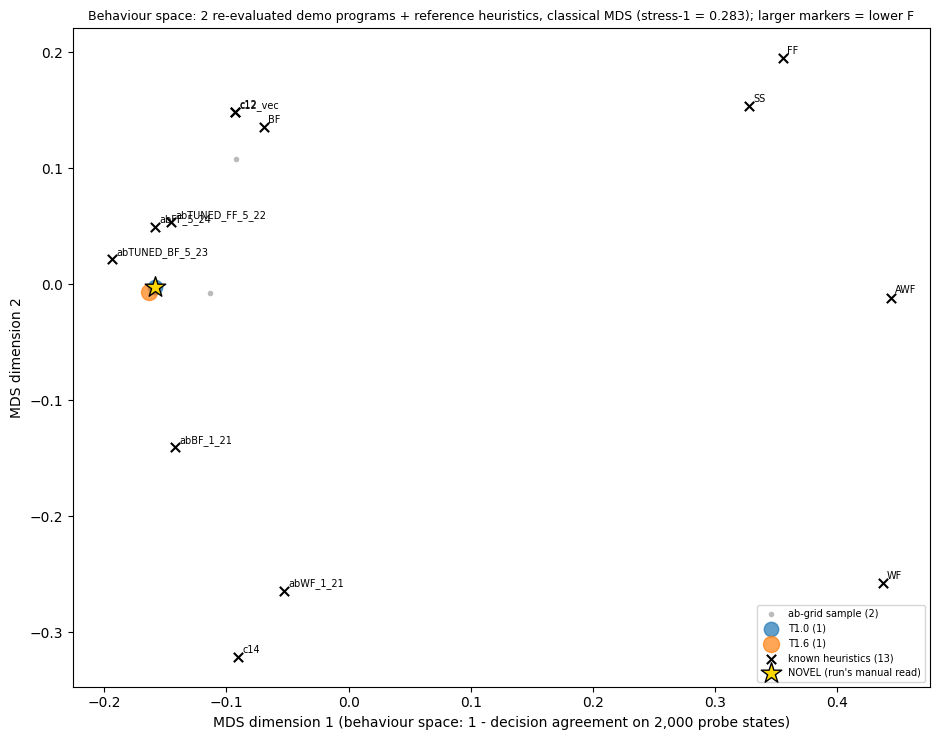

In [26]:
# src/figures.py: the colours, classical_mds (verbatim) and figure F4, drawn from the live probe vectors of the demo
# programs. The run's F4 used the best program of each behaviour cluster, the top 300 by F, over all 22,000 calls.
COL = {"T1.0": "#1f77b4", "T1.6": "#ff7f0e", "DTB": "#d62728", "RPB": "#9467bd", "IDEA": "#2ca02c", "NS": "#7f7f7f",
       "corpus": "#000000"}


def classical_mds(Dist: np.ndarray, k: int = 2) -> tuple[np.ndarray, float]:
    n = len(Dist)
    J = np.eye(n) - np.ones((n, n)) / n
    Bm = -0.5 * J @ (Dist ** 2) @ J
    w, V = np.linalg.eigh(Bm)
    idx = np.argsort(w)[::-1][:k]
    X = V[:, idx] * np.sqrt(np.maximum(w[idx], 0))
    dhat = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
    iu = np.triu_indices(n, 1)
    stress = float(np.sqrt(((Dist[iu] - dhat[iu]) ** 2).sum() / (Dist[iu] ** 2).sum()))
    return X, stress


pts = [(r["F"], r["arm"], r["pid"], LIVE_DEC[r["pid"]], r) for r in LIVE_ROWS
       if analysis.valid(r) and not r.get("probe_failed")]
pts.sort(key=lambda p: p[0])
pts = pts[:N_MDS]
V = np.concatenate([np.array([p[3] for p in pts], dtype=np.uint16).reshape(-1, cluster.N_STATES), CV, ABV])
C_ = cluster.agree_counts(V)
Dist = 1.0 - C_ / cluster.N_STATES
np.fill_diagonal(Dist, 0.0)
Dist = np.maximum(Dist, Dist.T)
X, stress = classical_mds(Dist)
off, off2 = len(pts), len(pts) + len(CV)
fig, ax = plt.subplots(figsize=(9.5, 7.5))
if len(ABV):
    ax.scatter(X[off2:, 0], X[off2:, 1], s=9, color="#bbbbbb", label=f"ab-grid sample ({len(ABV)})", zorder=1)
for arm in ["T1.0", "T1.6", "DTB", "RPB", "IDEA", "NS"]:
    m = [i for i, p in enumerate(pts) if p[1] == arm]
    if m:
        ax.scatter(X[m, 0], X[m, 1], s=[25 + 300 * max(0.0, 1.05 - pts[i][0]) for i in m], color=COL[arm],
                   label=f"{arm} ({len(m)})", alpha=0.7, zorder=3)
ax.scatter(X[off:off2, 0], X[off:off2, 1], s=45, marker="x", color="k", label=f"known heuristics ({len(CV)})", zorder=4)
for j, e in enumerate(ents):
    ax.annotate(e["name"], X[off + j], fontsize=7, xytext=(3, 3), textcoords="offset points")
nov = [i for i, p in enumerate(pts) if (p[4]["v3_class"] or {}).get("final_class") == "NOVEL"]
if nov:
    ax.scatter(X[nov, 0], X[nov, 1], s=240, marker="*", color="gold", edgecolor="k", label="NOVEL (run's manual read)",
               zorder=5)
ax.set_xlabel("MDS dimension 1 (behaviour space: 1 - decision agreement on 2,000 probe states)")
ax.set_ylabel("MDS dimension 2")
ax.set_title(f"Behaviour space: {len(pts)} re-evaluated demo programs + reference heuristics, classical MDS "
             f"(stress-1 = {stress:.3f}); larger markers = lower F", fontsize=9)
ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

### Held-out plane and decision-token positions

- **Left:** every held-out-evaluated program, placed by its excess on H-FSW5k (x) and H-OR3 (y). V1 requires an arm's best program to land in the shaded lower-left box (≤ 0.8 × best fit on both sets).
- **Right:** the top-20 entropy of the first 48 generated tokens for the demo's DTB and RPB calls, with the forced position marked. DTB forks where the model hesitates most; RPB forks anywhere.

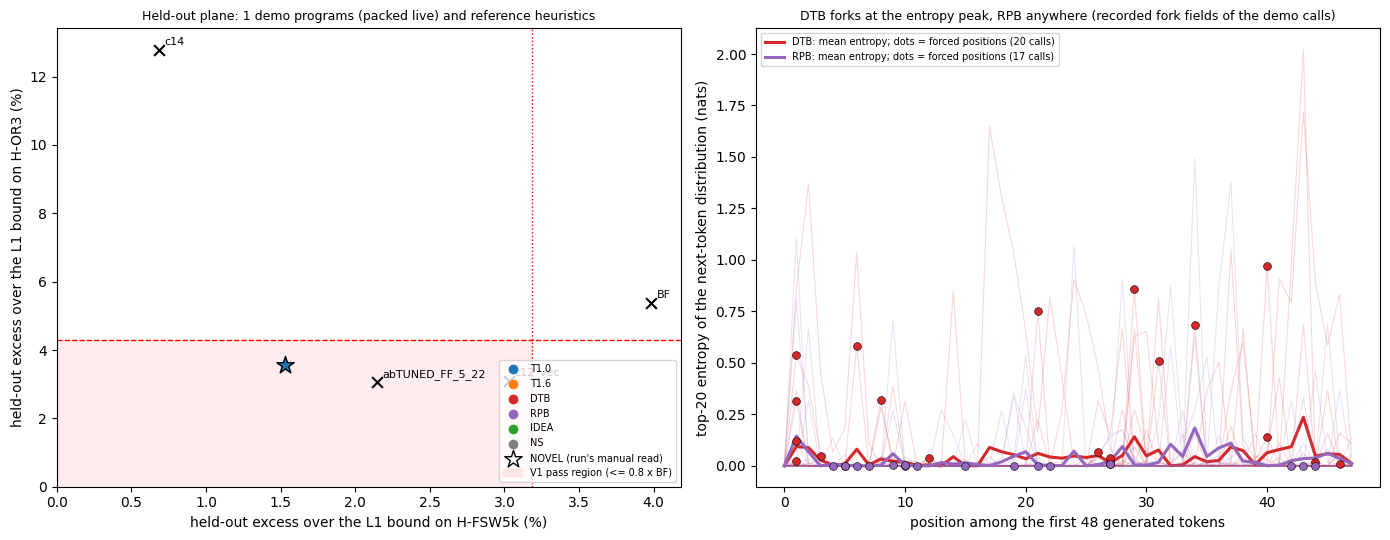

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
# ---- left: the held-out plane (live held-out excess of every program evaluated in section 12)
for pid, h in HO.items():
    r = next(x for x in LIVE_ROWS if x["pid"] == pid)
    e = h["heldout_excess_pct"]
    if e.get("H-FSW5k") is None or e.get("H-OR3") is None:
        continue
    novel = (r["v3_class"] or {}).get("final_class") == "NOVEL"
    ax1.scatter(e["H-FSW5k"], e["H-OR3"], s=170 if novel else 55, marker="*" if novel else "o", color=COL[r["arm"]],
                edgecolor="k" if novel else "none", zorder=3)
for arm in ARMS_MAIN + ["NS"]:
    ax1.scatter([], [], color=COL[arm], label=arm)
ax1.scatter([], [], marker="*", s=170, color="w", edgecolor="k", label="NOVEL (run's manual read)")
for k, e in REF_HO.items():
    ax1.scatter(e["H-FSW5k"], e["H-OR3"], marker="x", s=60, color="k", zorder=4)
    ax1.annotate(k, (e["H-FSW5k"], e["H-OR3"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax1.axvline(analysis.THR_FSW5K, color="r", ls=":", lw=1)
ax1.axhline(analysis.THR_OR3, color="r", ls="--", lw=1)
ax1.fill_between([0, analysis.THR_FSW5K], 0, analysis.THR_OR3, color="r", alpha=0.07, label="V1 pass region (<= 0.8 x BF)")
ax1.set_xlim(left=0)
ax1.set_ylim(bottom=0)
ax1.set_xlabel("held-out excess over the L1 bound on H-FSW5k (%)")
ax1.set_ylabel("held-out excess over the L1 bound on H-OR3 (%)")
ax1.set_title(f"Held-out plane: {len(HO)} demo programs (packed live) and reference heuristics", fontsize=9)
ax1.legend(fontsize=7, loc="lower right")
# ---- right: where DTB and RPB forced their token, on the recorded REQ1 entropies of the demo calls
for arm in ("DTB", "RPB"):
    fs = [r["fork"] for r in rows_all if r["arm"] == arm and r["fork"] and not r["fork"].get("unforced")]
    for f in fs:
        ax2.plot(range(len(f["H"])), f["H"], color=COL[arm], alpha=0.18, lw=0.8)
        ax2.scatter(f["j"], f["H"][f["j"]], color=COL[arm], s=32, zorder=3, edgecolor="k", lw=0.4)
    H = np.full((len(fs), REQ1_TOKENS), np.nan)
    for i, f in enumerate(fs):
        H[i, :len(f["H"])] = f["H"]
    ax2.plot(np.arange(REQ1_TOKENS), np.nanmean(H, 0), color=COL[arm], lw=2.2,
             label=f"{arm}: mean entropy; dots = forced positions ({len(fs)} calls)")
ax2.set_xlabel("position among the first 48 generated tokens")
ax2.set_ylabel("top-20 entropy of the next-token distribution (nats)")
ax2.set_title("DTB forks at the entropy peak, RPB anywhere (recorded fork fields of the demo calls)", fontsize=9)
ax2.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Scaling up to the full run

- **The whole demo subset.** Raise `N_PROGRAMS` to 96 and `N_HELDOUT` to 22 in the config cell. The comments there also give the original full-run values.
- **The full analysis.** Run `uv run method.py post judges v5 final` in the artifact folder. It needs the artifact's raw rows (`data/main/` and `data/ns/`: 22,000 calls with their decision vectors).
- **A new search.** This additionally needs a 24 GB GPU for Qwen3-8B-FP8 (`bash start_vllm.sh`, then `uv run method.py search ns`).

Every analysis after the search is deterministic given the raw rows. The exception is programs that call `np.random`: one NOVEL program does, which is why the config cell seeds numpy's global RNG.